### 📊 ChurnGuard AI — 1 : EDA pure (Telco Customer Churn)

Ce notebook est une **analyse exploratoire pure** : on observe, on mesure, on visualise. Rien d'autre.

### 🧭 Plan
| # | Section | Question à laquelle on répond |
|---|---|---|
| 1 | Vue d'ensemble | Que contient le jeu de données ? |
| 2 | Qualité des données | Les données sont-elles propres et cohérentes ? |
| 3 | Variable cible | Quel est le taux de churn, et le jeu est-il déséquilibré ? |
| 4 | Univarié numérique | Comment se distribuent tenure, MonthlyCharges, TotalCharges ? |
| 5 | Univarié catégoriel | Quelle est la composition de la base clients ? |
| 6 | Catégorielles vs Churn | Quelles modalités font partir les clients ? |
| 7 | Numériques vs Churn | Les churners ont-ils un profil numérique différent ? |
| 8 | Multivarié | Quelles variables sont liées entre elles, et quelles interactions comptent ? |
| 9 | Segments à risque | Où se concentre le churn ? |
| 10 | Impact business | Combien de revenu est en jeu ? |
| 11 | Lentille Responsible AI | Les attributs sensibles influencent-ils le churn ? Y a-t-il des proxys ? |
| 12 | Synthèse | Quels sont les enseignements clés (générés automatiquement) ? |

## 0. Configuration & chargement

In [ ]:
import warnings, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sns.set_theme(style='whitegrid', context='notebook')
C_STAY, C_CHURN, C_MAIN, C_GREY = '#2A9D8F', '#E76F51', '#264653', '#8D99AE'
PALETTE = {'No': C_STAY, 'Yes': C_CHURN}
plt.rcParams.update({
    'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
})


def h(text):
    display(Markdown(text))

In [8]:
# --- Chargement (lecture seule) -------------------------------------------------
path = r"C:\Users\pc\Desktop\DATA\Hackathon_churn\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(path)         
print(f'Fichier chargé : {path}  →  {df.shape[0]:,} lignes × {df.shape[1]} colonnes')

# Photographie de l'état initial (servira au contrôle d'intégrité final)
SNAPSHOT = {
    'shape': df.shape,
    'columns': list(df.columns),
    'dtypes': df.dtypes.astype(str).to_dict(),
    'hash': int(pd.util.hash_pandas_object(df, index=True).sum()),
}

Fichier chargé : C:\Users\pc\Desktop\DATA\Hackathon_churn\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv  →  7,043 lignes × 21 colonnes


In [9]:
# --- Rôles des colonnes (simple étiquetage, rien n'est transformé) ---------------
ID, TARGET = 'customerID', 'Churn'
NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']
SENSITIVE = ['gender', 'SeniorCitizen']
CAT = [c for c in df.columns if c not in [ID, TARGET] + NUM]       # SeniorCitizen incluse (0/1 tel quel)

# --- Vues d'analyse en LECTURE SEULE (jamais ajoutées à df) ----------------------
total_charges = pd.to_numeric(df['TotalCharges'], errors='coerce')   # TotalCharges est du texte dans df ; vue numérique pour l'analyse
churn_mask    = (df[TARGET] == 'Yes')                                # masque booléen, pas un encodage stocké
overall_rate  = churn_mask.mean()

print('Colonnes catégorielles analysées :', len(CAT))
print('Taux de churn global             :', f'{overall_rate:.2%}')

Colonnes catégorielles analysées : 16
Taux de churn global             : 26.54%


### Fonctions utilitaires (calculs statistiques)

In [10]:
def cramers_v(x, y):
    # V de Cramér corrigé du biais + chi² + p-value. Travaille sur un tableau croisé, sans aucun encodage.
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan, np.nan, np.nan
    chi2, p, dof, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.values.sum()
    r, k = ct.shape
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return (np.sqrt(phi2c / denom) if denom > 0 else np.nan), chi2, p

def wilson(k, n, z=1.96):
    # Intervalle de confiance de Wilson à 95 % pour une proportion.
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - half, c + half

def strength(v):
    if pd.isna(v): return 'n/a'
    return 'très faible' if v < 0.1 else 'faible' if v < 0.2 else 'modérée' if v < 0.3 else 'forte'

def effect_label(d):
    d = abs(d)
    return 'négligeable' if d < 0.2 else 'petit' if d < 0.5 else 'moyen' if d < 0.8 else 'grand'

---
## 1. Vue d'ensemble
**Objectif :** comprendre la structure : taille, types, rôle de chaque colonne, premiers exemples.

In [11]:
h('### 1.1 Dimensions, mémoire et dictionnaire des colonnes')
print(f"Lignes : {df.shape[0]:,}   |   Colonnes : {df.shape[1]}   |   Mémoire : {df.memory_usage(deep=True).sum() / 1024**2:.2f} Mo")

info = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notna().sum(),
    'n_unique': df.nunique(),
    'exemples': [', '.join(map(str, df[c].dropna().unique()[:4])) for c in df.columns],
})
display(info)

roles = pd.Series({c: ('Identifiant' if c == ID else 'Cible' if c == TARGET else 'Numérique' if c in NUM
                       else 'Catégorielle sensible' if c in SENSITIVE else 'Catégorielle') for c in df.columns})
display(roles.groupby(roles).apply(lambda s: ', '.join(s.index)).to_frame('colonnes'))

### 1.1 Dimensions, mémoire et dictionnaire des colonnes

Lignes : 7,043   |   Colonnes : 21   |   Mémoire : 6.82 Mo


,dtype,non_null,n_unique,exemples
customerID,str,7043,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW"
gender,str,7043,2,"Female, Male"
SeniorCitizen,int64,7043,2,"0, 1"
Partner,str,7043,2,"Yes, No"
Dependents,str,7043,2,"No, Yes"
tenure,int64,7043,73,"1, 34, 2, 45"
PhoneService,str,7043,2,"No, Yes"
MultipleLines,str,7043,3,"No phone service, No, Yes"
InternetService,str,7043,3,"DSL, Fiber optic, No"
OnlineSecurity,str,7043,3,"No, Yes, No internet service"


,colonnes
Catégorielle,"Partner, Dependents, PhoneService, MultipleLin..."
Catégorielle sensible,"gender, SeniorCitizen"
Cible,Churn
Identifiant,customerID
Numérique,"tenure, MonthlyCharges, TotalCharges"


In [12]:
h('### 1.2 Aperçu des données')
display(df.head(8))
display(df.sample(6, random_state=42))

### 1.2 Aperçu des données

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.650,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.100,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.750,301.9,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,24.800,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.250,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.350,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,No,Yes,No,No,No,Month-to-month,No,Electronic check,76.350,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,No,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.550,3260.1,No
1263,6818-WOBHJ,Female,1,Yes,No,68,Yes,Yes,Fiber optic,No,Yes,No,No,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.600,6127.6,Yes


In [13]:
h('### 1.3 Statistiques descriptives brutes')
display(df.describe(include='all').T)

### 1.3 Statistiques descriptives brutes

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,"7,043.000",NaN,NaN,NaN,0.162,0.369,0.000,0.000,0.000,0.000,1.000
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,"7,043.000",NaN,NaN,NaN,32.371,24.559,0.000,9.000,29.000,55.000,72.000
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


---
## 2. Qualité des données
**Objectif :** détecter tout ce qui est anormal

### 2.1 Valeurs manquantes et chaînes vides / espaces

,NaN,chaînes vides ou espaces,total,pct
TotalCharges,0,11,11,0.156


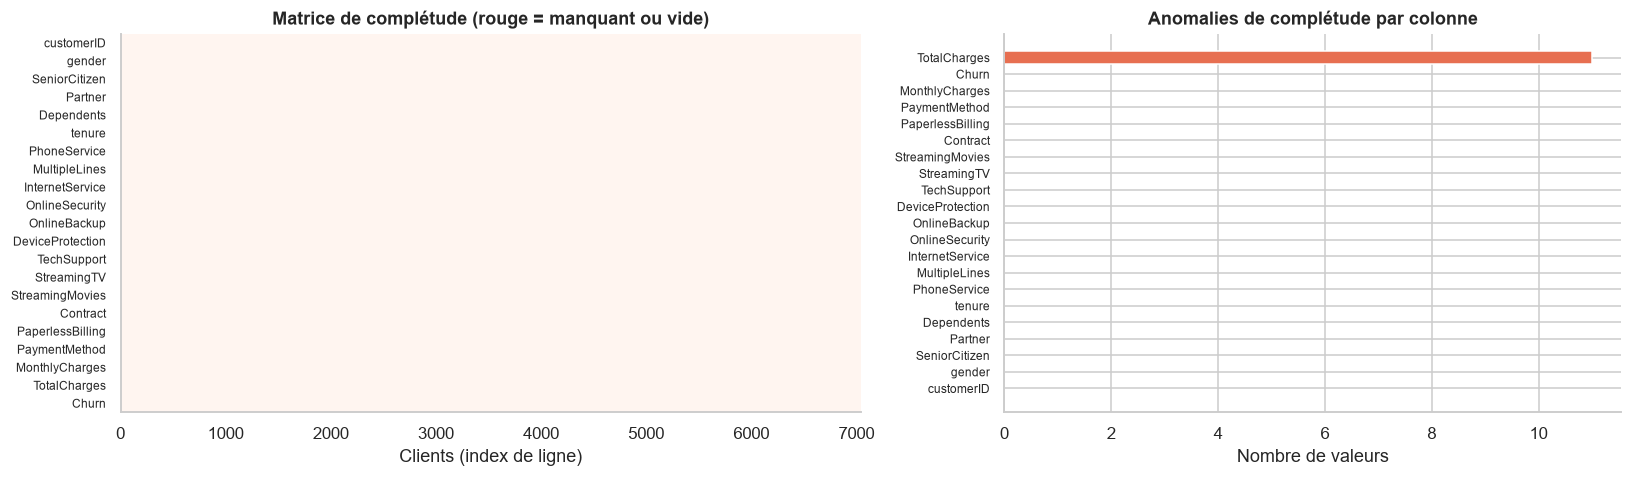

In [14]:
h('### 2.1 Valeurs manquantes et chaînes vides / espaces')
obj_cols = df.select_dtypes(include=['object', 'string']).columns
blank = {c: int(df[c].astype(str).str.strip().eq('').sum()) for c in obj_cols}
quality = pd.DataFrame({
    'NaN': df.isna().sum(),
    'chaînes vides ou espaces': pd.Series(blank).reindex(df.columns).fillna(0).astype(int),
})
quality['total'] = quality.sum(axis=1)
quality['pct'] = quality['total'] / len(df) * 100
display(quality[quality['total'] > 0] if (quality['total'] > 0).any() else pd.DataFrame({'résultat': ['Aucune valeur manquante détectée']}))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1.2, 1]})
# matrice de complétude
gap_mask = pd.DataFrame({c: df[c].isna() | df[c].astype(str).str.strip().eq('') for c in df.columns})
ax[0].imshow(gap_mask.T.values, aspect='auto', cmap='Reds', interpolation='nearest')
ax[0].set_yticks(range(len(df.columns)))
ax[0].set_yticklabels(df.columns, fontsize=8)
ax[0].set_xlabel('Clients (index de ligne)')
ax[0].set_title('Matrice de complétude (rouge = manquant ou vide)')
ax[0].grid(False)
# barres
q = quality.sort_values('total')
ax[1].barh(q.index, q['total'], color=[C_CHURN if v > 0 else C_STAY for v in q['total']])
ax[1].set_title('Anomalies de complétude par colonne')
ax[1].set_xlabel('Nombre de valeurs')
ax[1].tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

In [15]:
h('### 2.2 Doublons')
dup_rows = int(df.duplicated().sum())
dup_id = int(df[ID].duplicated().sum())
dup_wo_id = int(df.drop(columns=ID).duplicated().sum())
display(pd.DataFrame({'contrôle': ['Lignes entièrement dupliquées', 'customerID dupliqués', 'Lignes identiques hors customerID'],
                      'nombre': [dup_rows, dup_id, dup_wo_id]}))
print('→ customerID est un identifiant unique.' if dup_id == 0 else '→ ATTENTION : customerID n\'est pas unique.')
if dup_wo_id > 0:
    print(f'→ {dup_wo_id} profils identiques hors ID : plausible (clients au même contrat/forfait), à ne pas confondre avec des doublons.')

### 2.2 Doublons

,contrôle,nombre
0,Lignes entièrement dupliquées,0
1,customerID dupliqués,0
2,Lignes identiques hors customerID,22


→ customerID est un identifiant unique.
→ 22 profils identiques hors ID : plausible (clients au même contrat/forfait), à ne pas confondre avec des doublons.


In [16]:
h('### 2.3 Colonne TotalCharges : stockée en texte, valeurs non numériques')
bad = total_charges.isna()
print(f"dtype de TotalCharges dans df : {df['TotalCharges'].dtype}")
print(f"Valeurs non convertibles en nombre : {int(bad.sum())}")
if bad.any():
    display(df.loc[bad, [ID, 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].head(15))
    print('Valeurs de tenure de ces lignes :', sorted(df.loc[bad, 'tenure'].unique()))
    print('Valeurs brutes distinctes        :', [repr(v) for v in df.loc[bad, 'TotalCharges'].unique()])
    print('Répartition du churn parmi ces lignes :', df.loc[bad, 'Churn'].value_counts().to_dict())

### 2.3 Colonne TotalCharges : stockée en texte, valeurs non numériques

dtype de TotalCharges dans df : str
Valeurs non convertibles en nombre : 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.550,,No
753,3115-CZMZD,0,20.250,,No
936,5709-LVOEQ,0,80.850,,No
1082,4367-NUYAO,0,25.750,,No
1340,1371-DWPAZ,0,56.050,,No
3331,7644-OMVMY,0,19.850,,No
3826,3213-VVOLG,0,25.350,,No
4380,2520-SGTTA,0,20.000,,No
5218,2923-ARZLG,0,19.700,,No
6670,4075-WKNIU,0,73.350,,No


Valeurs de tenure de ces lignes : [np.int64(0)]
Valeurs brutes distinctes        : ["' '"]
Répartition du churn parmi ces lignes : {'No': 11}


### 2.4 Cohérence interne des données

,règle de cohérence,nb de violations / cas
0,InternetService='No' ⇔ OnlineSecurity='No inte...,0
1,InternetService='No' ⇔ OnlineBackup='No intern...,0
2,InternetService='No' ⇔ DeviceProtection='No in...,0
3,InternetService='No' ⇔ TechSupport='No interne...,0
4,InternetService='No' ⇔ StreamingTV='No interne...,0
5,InternetService='No' ⇔ StreamingMovies='No int...,0
6,PhoneService='No' ⇔ MultipleLines='No phone se...,0
7,tenure < 0,0
8,MonthlyCharges ≤ 0,0
9,tenure = 0,11



Écart relatif TotalCharges vs tenure×MonthlyCharges : médiane +0.0%, P5 -7.6%, P95 +7.5%
→ Les écarts viennent des changements de forfait au cours de la vie du contrat (normal).


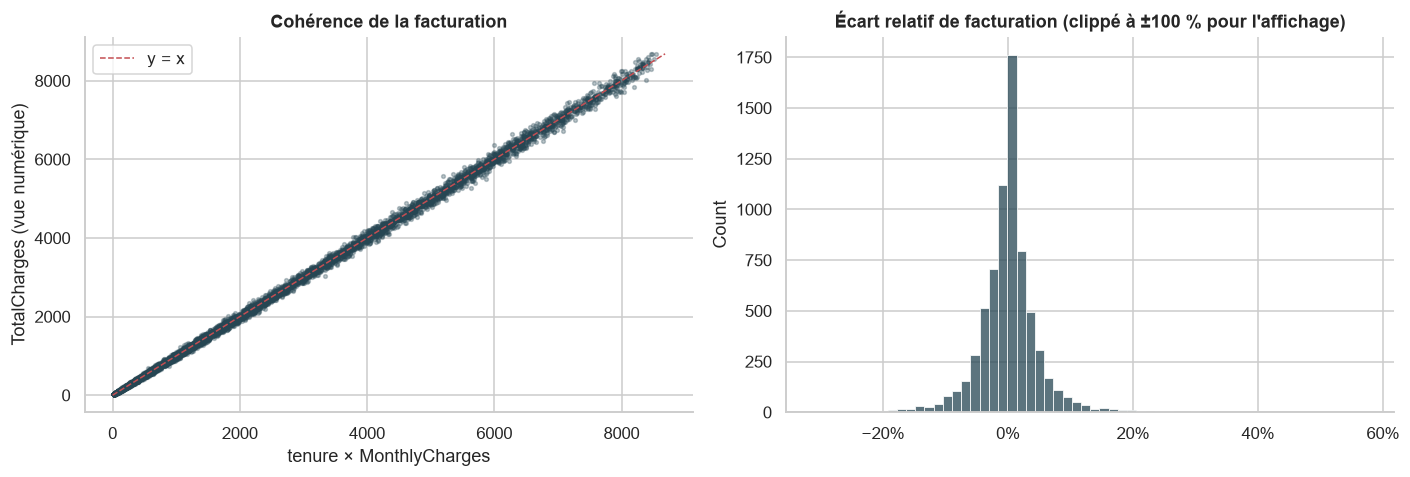

In [17]:
h('### 2.4 Cohérence interne des données')
rows = []
no_net = df['InternetService'].eq('No')
for c in [c for c in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'] if c in df.columns]:
    v = int((no_net & df[c].ne('No internet service')).sum() + (~no_net & df[c].eq('No internet service')).sum())
    rows.append((f"InternetService='No' ⇔ {c}='No internet service'", v))
if 'MultipleLines' in df.columns:
    no_ph = df['PhoneService'].eq('No')
    v = int((no_ph & df['MultipleLines'].ne('No phone service')).sum() + (~no_ph & df['MultipleLines'].eq('No phone service')).sum())
    rows.append(("PhoneService='No' ⇔ MultipleLines='No phone service'", v))
rows.append(('tenure < 0', int((df['tenure'] < 0).sum())))
rows.append(('MonthlyCharges ≤ 0', int((df['MonthlyCharges'] <= 0).sum())))
rows.append(('tenure = 0', int((df['tenure'] == 0).sum())))
rows.append(('tenure > 72 mois', int((df['tenure'] > 72).sum())))
display(pd.DataFrame(rows, columns=['règle de cohérence', 'nb de violations / cas']))

# Cohérence de facturation : TotalCharges ≈ tenure × MonthlyCharges ?
expected = df['tenure'] * df['MonthlyCharges']
valid = total_charges.notna() & (df['tenure'] > 0)
rel_gap = ((total_charges - expected) / expected)[valid]
print(f"\nÉcart relatif TotalCharges vs tenure×MonthlyCharges : médiane {rel_gap.median():+.1%}, "
      f"P5 {rel_gap.quantile(.05):+.1%}, P95 {rel_gap.quantile(.95):+.1%}")
print('→ Les écarts viennent des changements de forfait au cours de la vie du contrat (normal).')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(expected[valid], total_charges[valid], s=6, alpha=.3, color=C_MAIN)
lim = max(expected[valid].max(), total_charges[valid].max())
ax[0].plot([0, lim], [0, lim], 'r--', lw=1, label='y = x')
ax[0].set_xlabel('tenure × MonthlyCharges'); ax[0].set_ylabel('TotalCharges (vue numérique)')
ax[0].set_title('Cohérence de la facturation'); ax[0].legend()
sns.histplot(rel_gap.clip(-1, 1), bins=60, color=C_MAIN, ax=ax[1])
ax[1].set_title('Écart relatif de facturation (clippé à ±100 % pour l\'affichage)')
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.show()

### 2.5 Cardinalité et cohérence des libellés

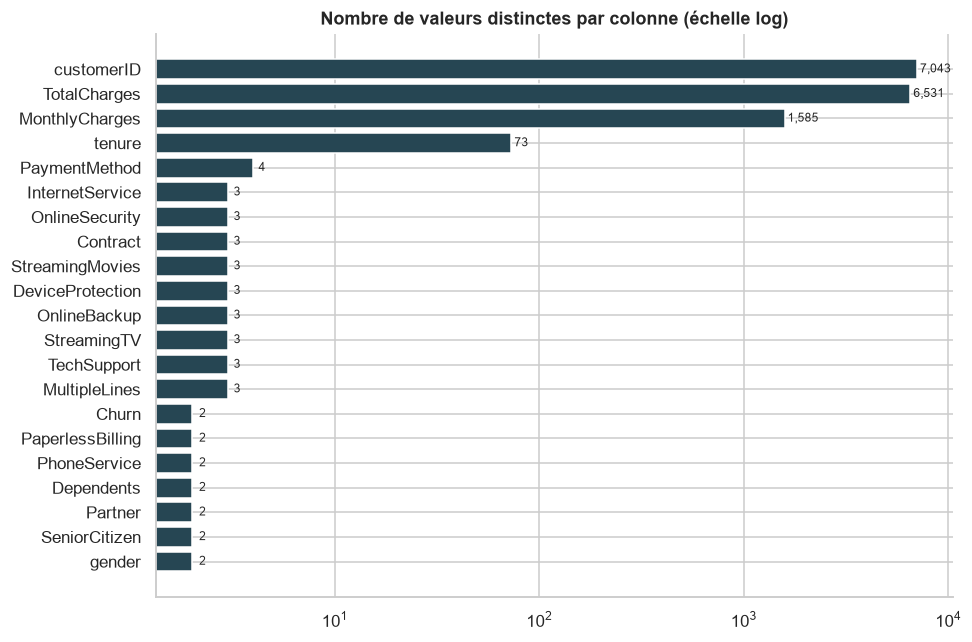

Colonnes avec variantes de casse/espaces : aucune


**Modalités de chaque variable catégorielle**

,modalités
gender,"[Female, Male]"
SeniorCitizen,"[0, 1]"
Partner,"[No, Yes]"
Dependents,"[No, Yes]"
PhoneService,"[No, Yes]"
MultipleLines,"[No, No phone service, Yes]"
InternetService,"[DSL, Fiber optic, No]"
OnlineSecurity,"[No, No internet service, Yes]"
OnlineBackup,"[No, No internet service, Yes]"
DeviceProtection,"[No, No internet service, Yes]"


In [18]:
h('### 2.5 Cardinalité et cohérence des libellés')
card = df.nunique().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(card.index, card.values, color=C_MAIN)
for i, v in enumerate(card.values):
    ax.text(v + .1 if v < 100 else v * 1.0, i, f' {v:,}', va='center', fontsize=8)
ax.set_xscale('log'); ax.set_title('Nombre de valeurs distinctes par colonne (échelle log)')
plt.tight_layout(); plt.show()

incons = []
for c in obj_cols:
    s = df[c].astype(str)
    if s.nunique() != s.str.strip().str.lower().nunique():
        incons.append(c)
print('Colonnes avec variantes de casse/espaces :', incons if incons else 'aucune')

h('**Modalités de chaque variable catégorielle**')
display(pd.DataFrame({c: [sorted(map(str, df[c].unique()))] for c in CAT + [TARGET]}, index=['modalités']).T)

In [45]:
h('### 2.6 Valeurs extrêmes (méthode IQR + z-score)')
num_views = {'tenure': df['tenure'], 'MonthlyCharges': df['MonthlyCharges'], 'TotalCharges (num.)': total_charges}
rows = []
for name, s in num_views.items():
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = np.abs(stats.zscore(s))
    rows.append({'variable': name, 'Q1': q1, 'Q3': q3, 'borne basse': lo, 'borne haute': hi,
                 'outliers IQR': int(((s < lo) | (s > hi)).sum()), 'outliers |z|>3': int((z > 3).sum())})
display(pd.DataFrame(rows).set_index('variable'))

### 2.6 Valeurs extrêmes (méthode IQR + z-score)

,Q1,Q3,borne basse,borne haute,outliers IQR,outliers |z|>3
variable,,,,,,
tenure,9.000,55.000,-60.000,124.000,0,0
MonthlyCharges,35.500,89.850,-46.025,171.375,0,0
TotalCharges (num.),401.450,"3,794.738","-4,688.481","8,884.669",0,0


---
## 3. Variable cible : Churn
**Objectif :** mesurer le taux de churn et le déséquilibre de classes (impact direct sur le choix des métriques plus tard).

,clients,part
Churn,,
No,5174,73.46%
Yes,1869,26.54%


Ratio de déséquilibre (restés / partis) : 2.77 : 1
Précision d'un modèle naïf « personne ne part » : 73.46%  → l'accuracy seule serait trompeuse.


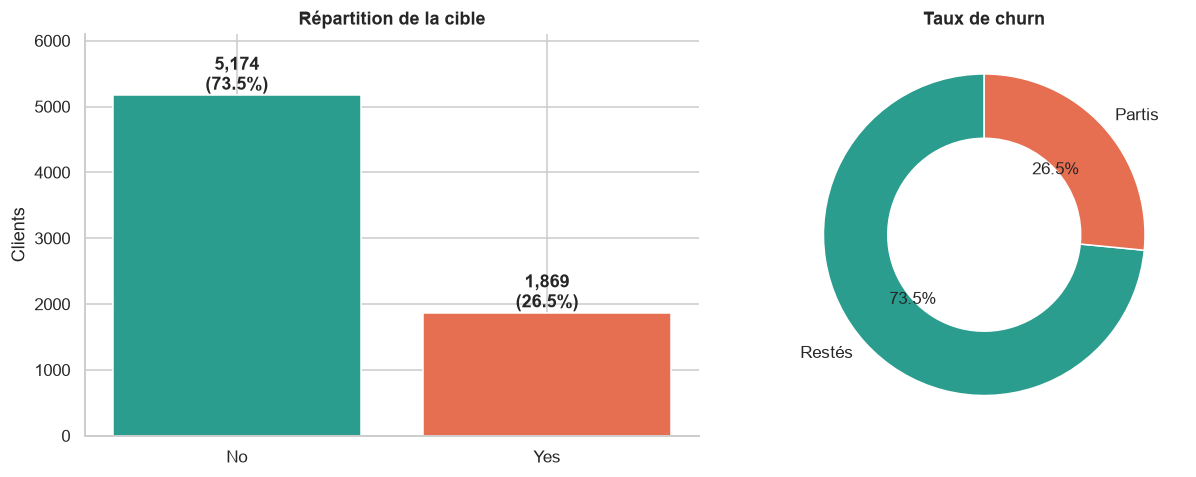

In [20]:
counts = df[TARGET].value_counts()
rates = df[TARGET].value_counts(normalize=True)
display(pd.DataFrame({'clients': counts, 'part': rates.map('{:.2%}'.format)}))

n_stay, n_churn = counts.get('No', 0), counts.get('Yes', 0)
print(f'Ratio de déséquilibre (restés / partis) : {n_stay / n_churn:.2f} : 1')
print(f'Précision d\'un modèle naïf « personne ne part » : {n_stay / len(df):.2%}  → l\'accuracy seule serait trompeuse.')

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
order = ['No', 'Yes']
ax[0].bar(order, [counts[o] for o in order], color=[PALETTE[o] for o in order])
for i, o in enumerate(order):
    ax[0].text(i, counts[o], f'{counts[o]:,}\n({rates[o]:.1%})', ha='center', va='bottom', fontweight='bold')
ax[0].set_title('Répartition de la cible'); ax[0].set_ylabel('Clients'); ax[0].set_ylim(0, counts.max() * 1.18)
ax[1].pie([counts[o] for o in order], labels=['Restés', 'Partis'], colors=[PALETTE[o] for o in order],
          autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=.4, edgecolor='white'), textprops={'fontsize': 11})
ax[1].set_title('Taux de churn')
plt.tight_layout(); plt.show()

---
## 4. Analyse univariée : variables numériques
**Objectif :** forme des distributions (asymétrie, multimodalité), tendance centrale, dispersion, normalité.

In [21]:
rows = []
for name, s in num_views.items():
    s = s.dropna()
    nt = stats.normaltest(s)
    rows.append({'variable': name, 'n': len(s), 'moyenne': s.mean(), 'médiane': s.median(), 'écart-type': s.std(),
                 'CV %': s.std() / s.mean() * 100, 'min': s.min(), 'P10': s.quantile(.1), 'P25': s.quantile(.25),
                 'P75': s.quantile(.75), 'P90': s.quantile(.9), 'max': s.max(),
                 'skewness': s.skew(), 'kurtosis': s.kurt(), 'p normalité': nt.pvalue})
display(pd.DataFrame(rows).set_index('variable').T)
print('Lecture : skewness ≠ 0 = asymétrie ; p normalité < 0,05 = distribution non gaussienne (méthodes non paramétriques privilégiées).')

variable,tenure,MonthlyCharges,TotalCharges (num.)
n,"7,043.000","7,043.000","7,032.000"
moyenne,32.371,64.762,"2,283.300"
médiane,29.000,70.350,"1,397.475"
écart-type,24.559,30.090,"2,266.771"
CV %,75.868,46.463,99.276
min,0.000,18.250,18.800
P10,2.000,20.050,84.600
P25,9.000,35.500,401.450
P75,55.000,89.850,"3,794.738"
P90,69.000,102.600,"5,976.640"


Lecture : skewness ≠ 0 = asymétrie ; p normalité < 0,05 = distribution non gaussienne (méthodes non paramétriques privilégiées).


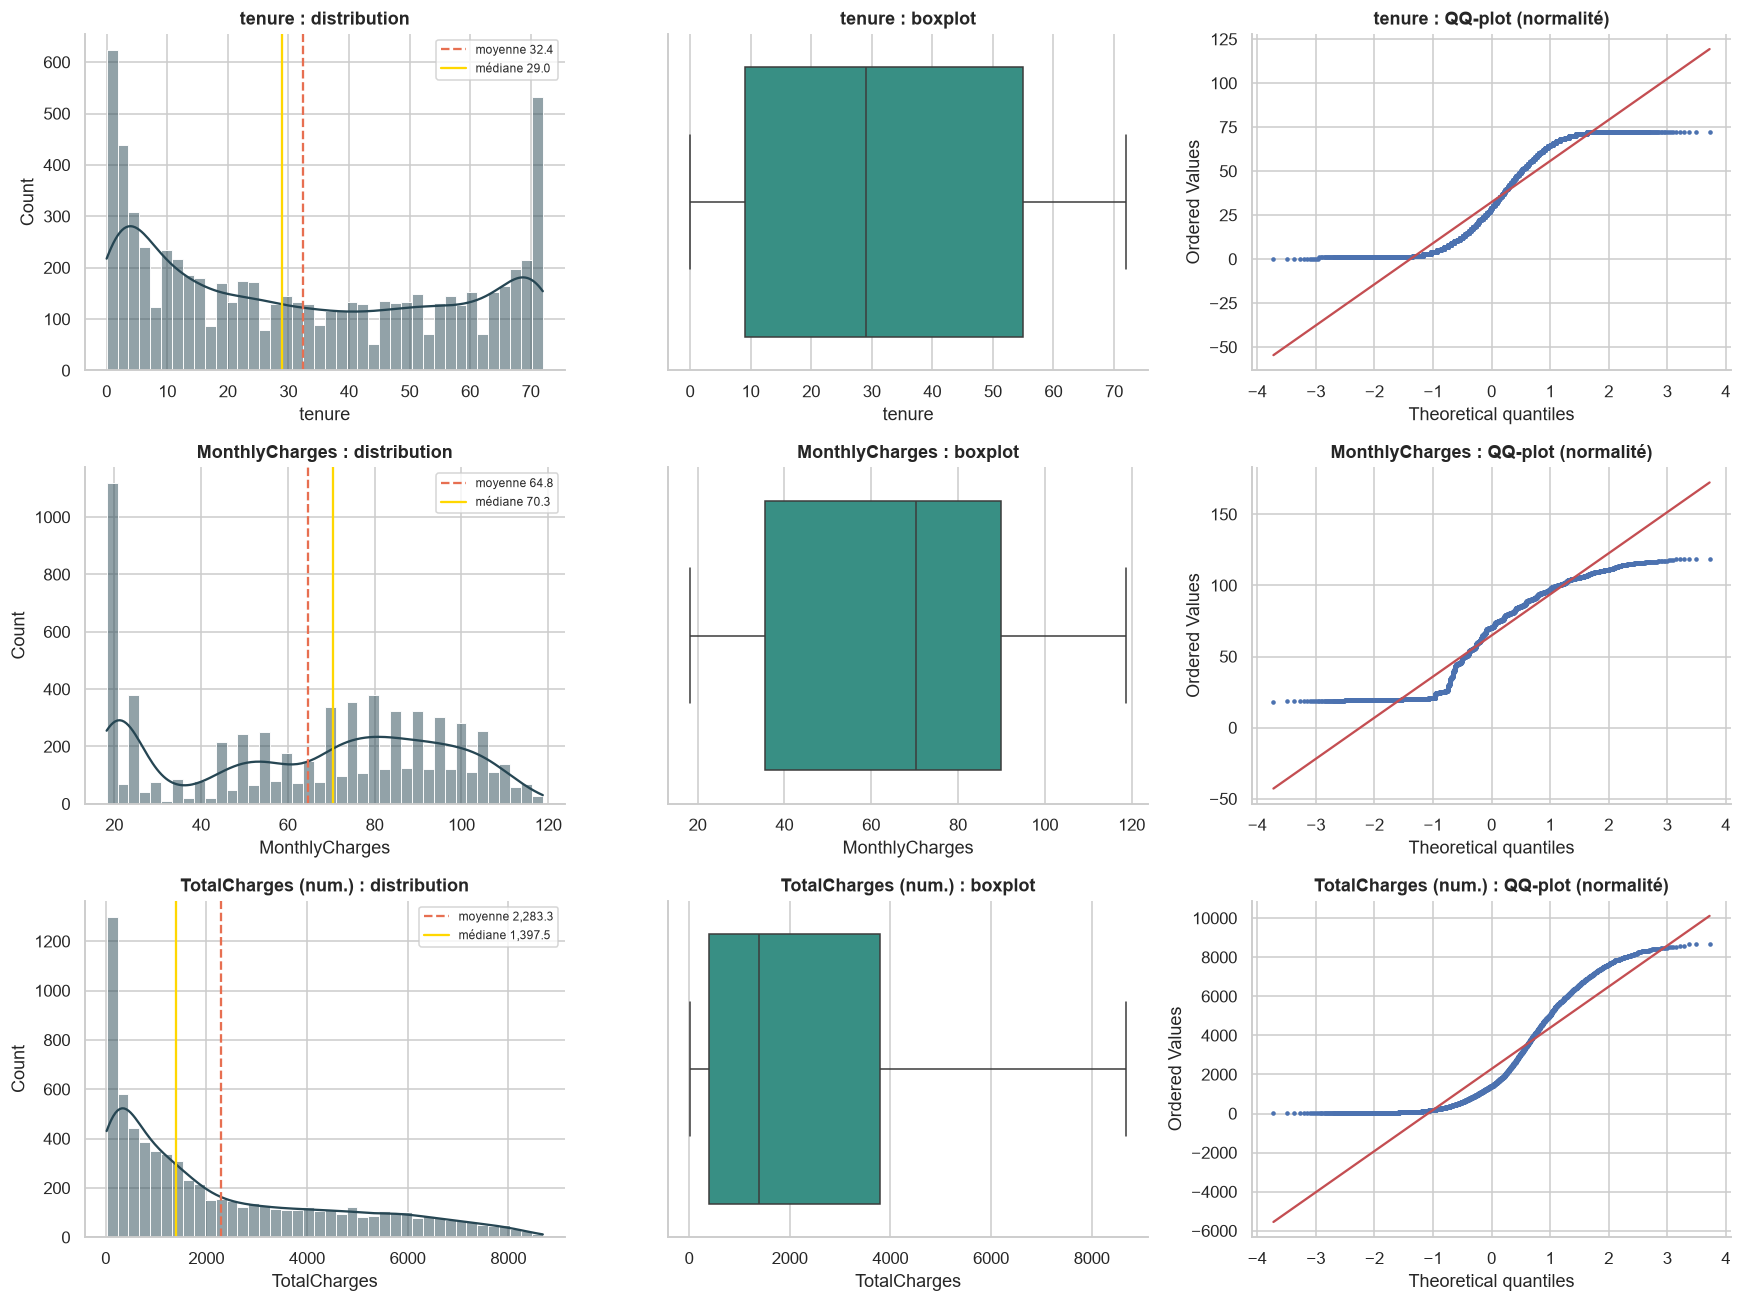

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for i, (name, s) in enumerate(num_views.items()):
    s = s.dropna()
    sns.histplot(s, kde=True, bins=40, color=C_MAIN, ax=axes[i, 0])
    axes[i, 0].axvline(s.mean(), color=C_CHURN, ls='--', label=f'moyenne {s.mean():,.1f}')
    axes[i, 0].axvline(s.median(), color='gold', ls='-', label=f'médiane {s.median():,.1f}')
    axes[i, 0].legend(fontsize=8); axes[i, 0].set_title(f'{name} : distribution')
    sns.boxplot(x=s, color=C_STAY, ax=axes[i, 1], fliersize=2); axes[i, 1].set_title(f'{name} : boxplot')
    stats.probplot(s, dist='norm', plot=axes[i, 2]); axes[i, 2].set_title(f'{name} : QQ-plot (normalité)')
    axes[i, 2].get_lines()[0].set_markersize(2)
plt.tight_layout(); plt.show()

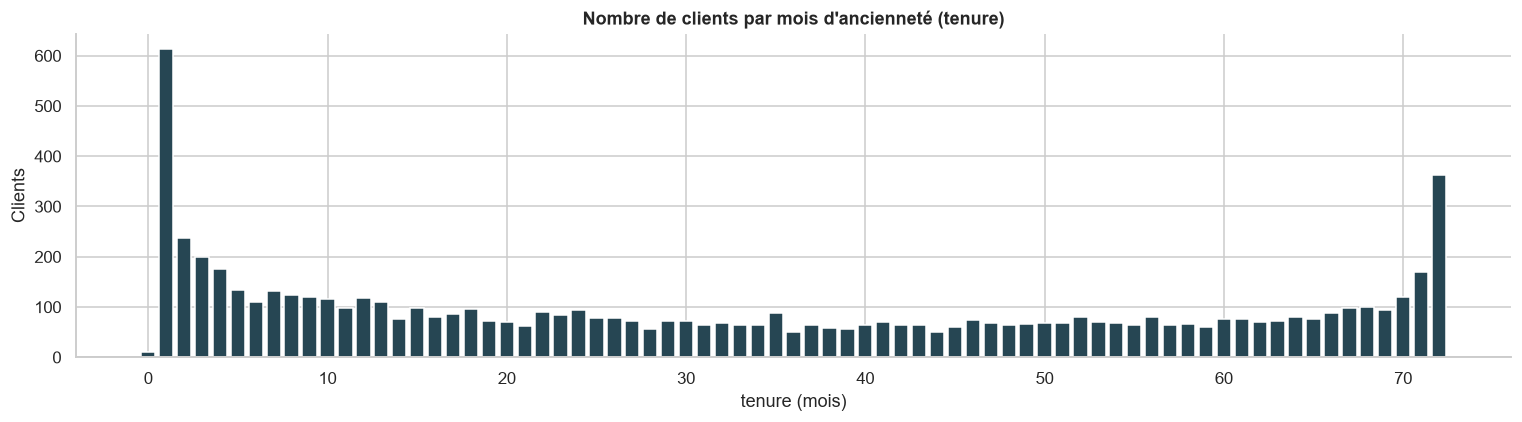

Clients avec tenure ≤ 6 mois : 21.0%   |   tenure ≥ 60 mois : 21.1%


In [23]:
# Granularité de tenure : nombre de clients par mois d'ancienneté (aucune tranche créée)
tc = df['tenure'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(tc.index, tc.values, color=C_MAIN)
ax.set_title('Nombre de clients par mois d\'ancienneté (tenure)'); ax.set_xlabel('tenure (mois)'); ax.set_ylabel('Clients')
plt.tight_layout(); plt.show()
print(f"Clients avec tenure ≤ 6 mois : {(df['tenure'] <= 6).mean():.1%}   |   tenure ≥ 60 mois : {(df['tenure'] >= 60).mean():.1%}")

---
## 5. Analyse univariée : variables catégorielles
**Objectif :** composition de la base clients, repérer les modalités rares ou dominantes.

In [24]:
summary = []
for c in CAT:
    vc = df[c].value_counts(normalize=True)
    ent = -(vc * np.log2(vc)).sum()
    summary.append({'variable': c, 'n_modalités': len(vc), 'modalité dominante': str(vc.index[0]),
                    'part dominante': vc.iloc[0], 'modalité la plus rare': str(vc.index[-1]), 'part la plus rare': vc.iloc[-1],
                    'entropie (bits)': ent})
cat_summary = pd.DataFrame(summary).set_index('variable')
display(cat_summary)
print('Variables avec une modalité < 5 % :', list(cat_summary.index[cat_summary['part la plus rare'] < .05]) or 'aucune')
print('Variables dominées à > 80 % par une modalité :', list(cat_summary.index[cat_summary['part dominante'] > .8]) or 'aucune')

,n_modalités,modalité dominante,part dominante,modalité la plus rare,part la plus rare,entropie (bits)
variable,,,,,,
gender,2,Male,0.505,Female,0.495,1.000
SeniorCitizen,2,0,0.838,1,0.162,0.639
Partner,2,No,0.517,Yes,0.483,0.999
Dependents,2,No,0.700,Yes,0.300,0.881
PhoneService,2,Yes,0.903,No,0.097,0.459
MultipleLines,3,No,0.481,No phone service,0.097,1.359
InternetService,3,Fiber optic,0.440,No,0.217,1.529
OnlineSecurity,3,No,0.497,No internet service,0.217,1.496
OnlineBackup,3,No,0.438,No internet service,0.217,1.529


Variables avec une modalité < 5 % : aucune
Variables dominées à > 80 % par une modalité : ['SeniorCitizen', 'PhoneService']


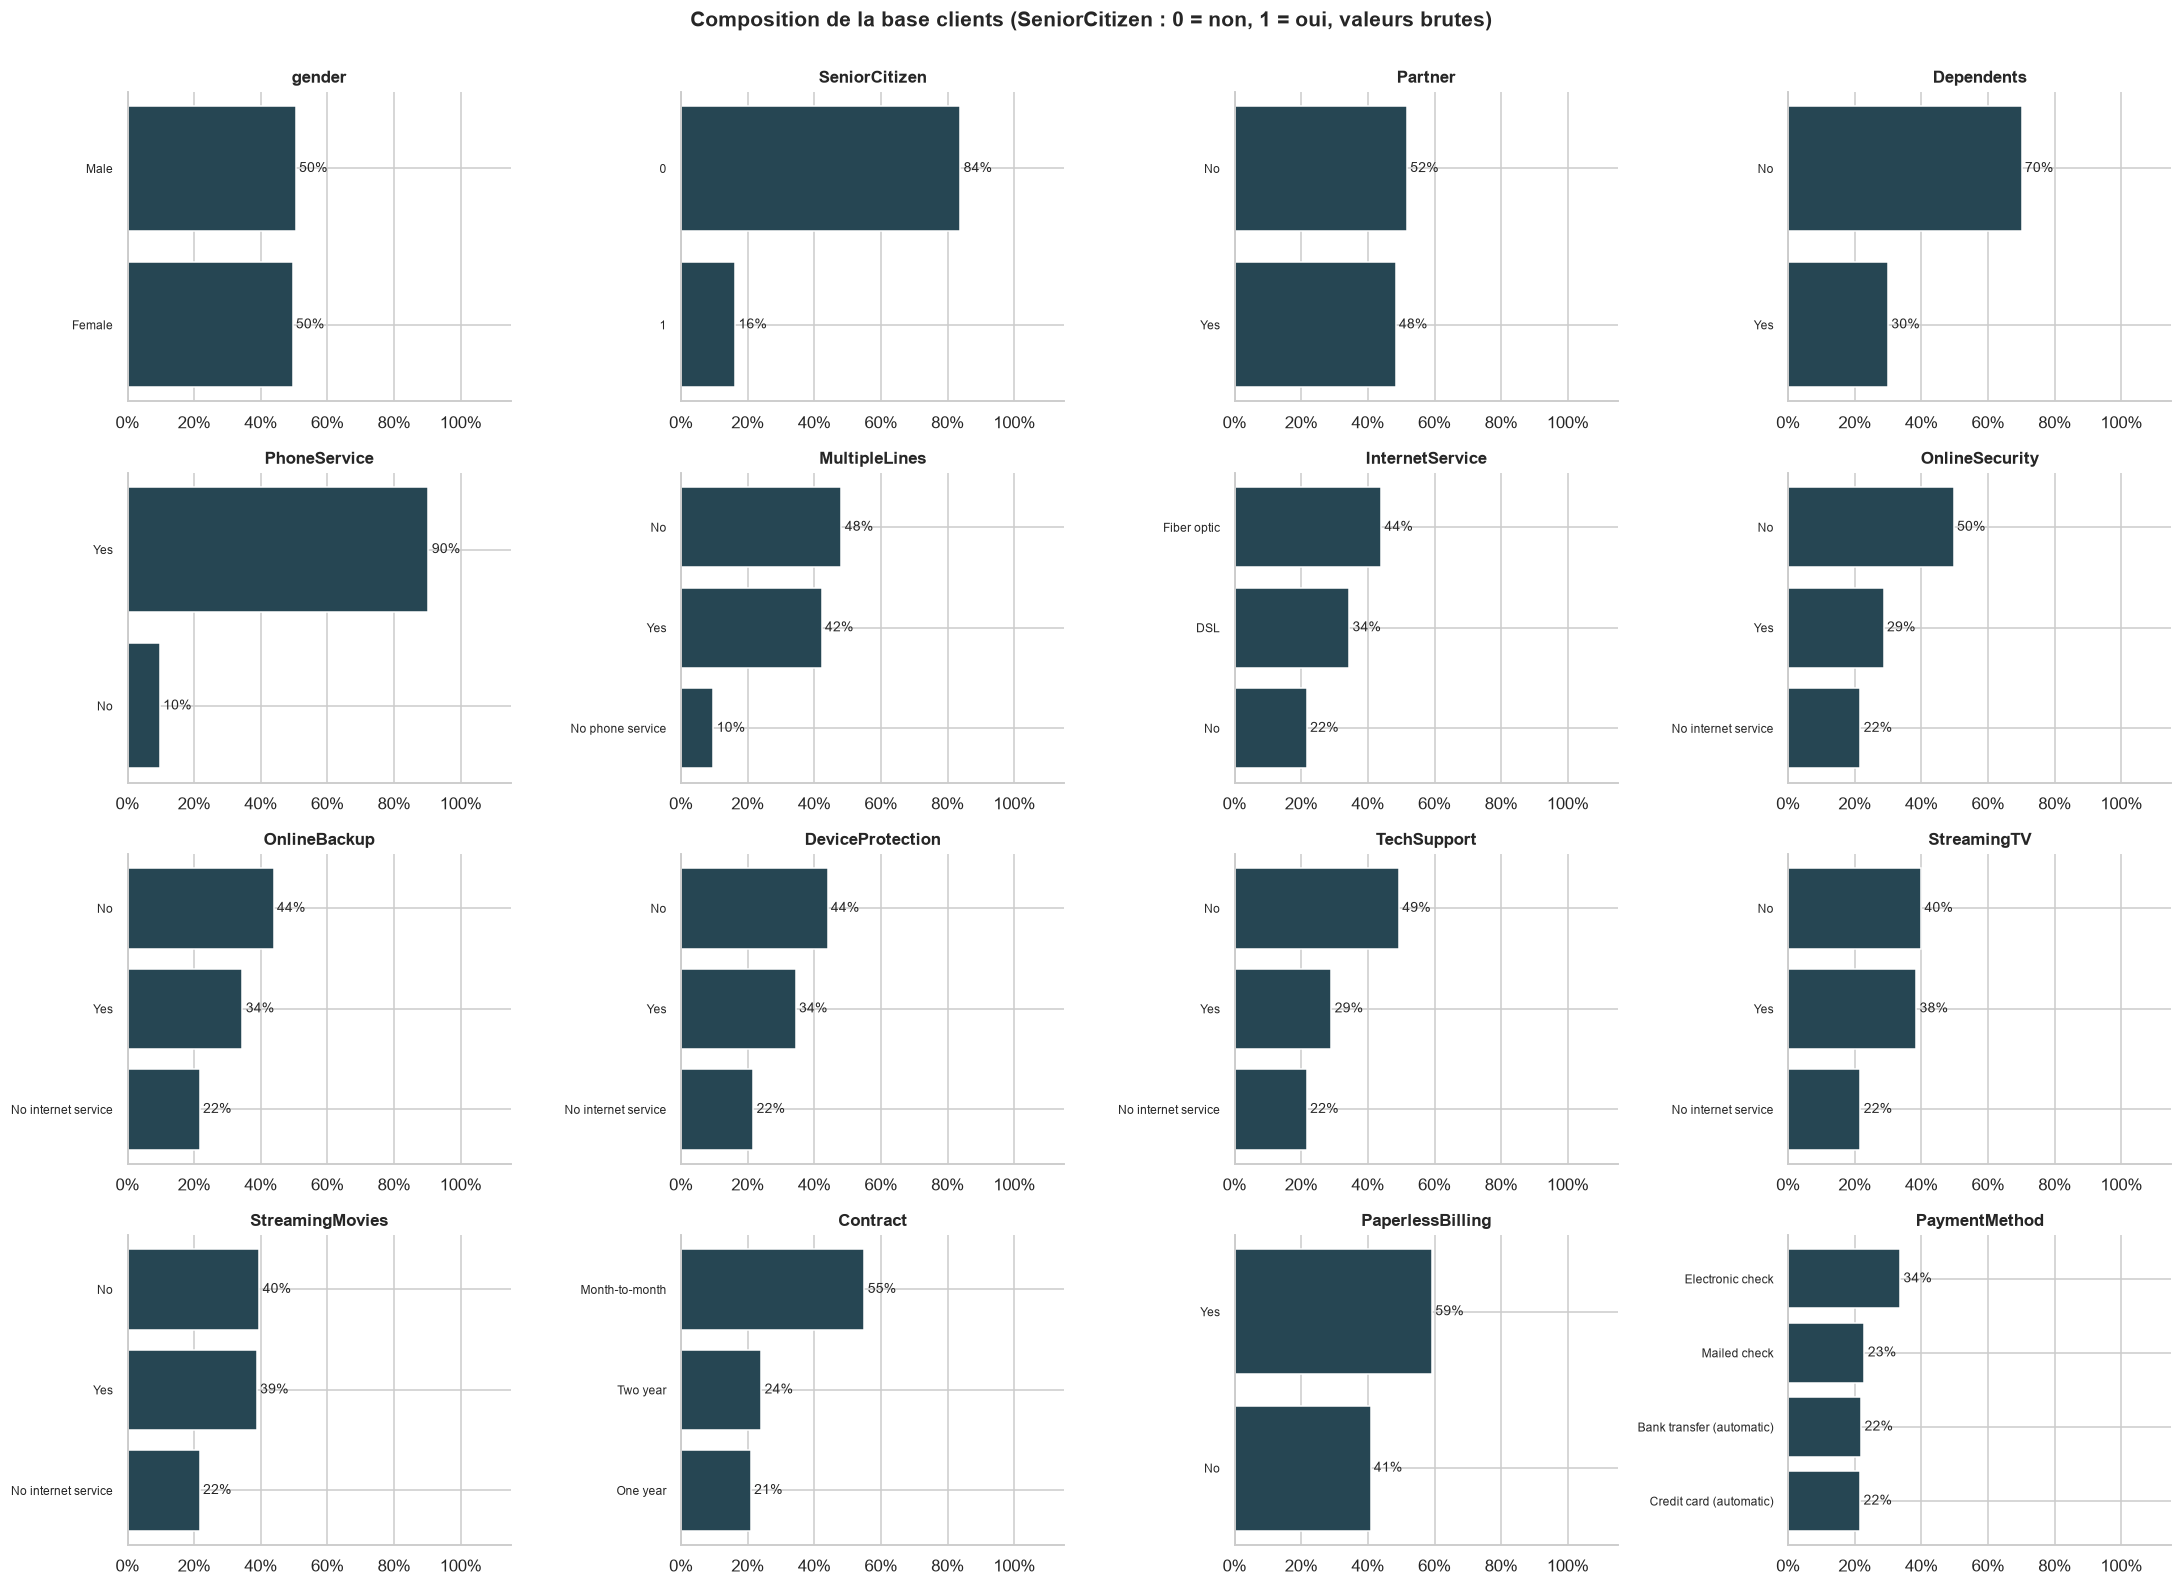

In [25]:
ncols = 4
nrows = int(np.ceil(len(CAT) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.6 * nrows))
for ax, c in zip(axes.ravel(), CAT):
    vc = df[c].value_counts(normalize=True).sort_values()
    ax.barh(vc.index.astype(str), vc.values, color=C_MAIN)
    for i, v in enumerate(vc.values):
        ax.text(v + .01, i, f'{v:.0%}', va='center', fontsize=9)
    ax.set_xlim(0, 1.15); ax.set_title(c, fontsize=11); ax.tick_params(axis='y', labelsize=8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for ax in axes.ravel()[len(CAT):]:
    ax.axis('off')
fig.suptitle('Composition de la base clients (SeniorCitizen : 0 = non, 1 = oui, valeurs brutes)', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

---
## 6. Variables catégorielles vs Churn
**Objectif :** identifier les modalités qui concentrent le churn et mesurer la force de chaque lien (V de Cramér + chi²).

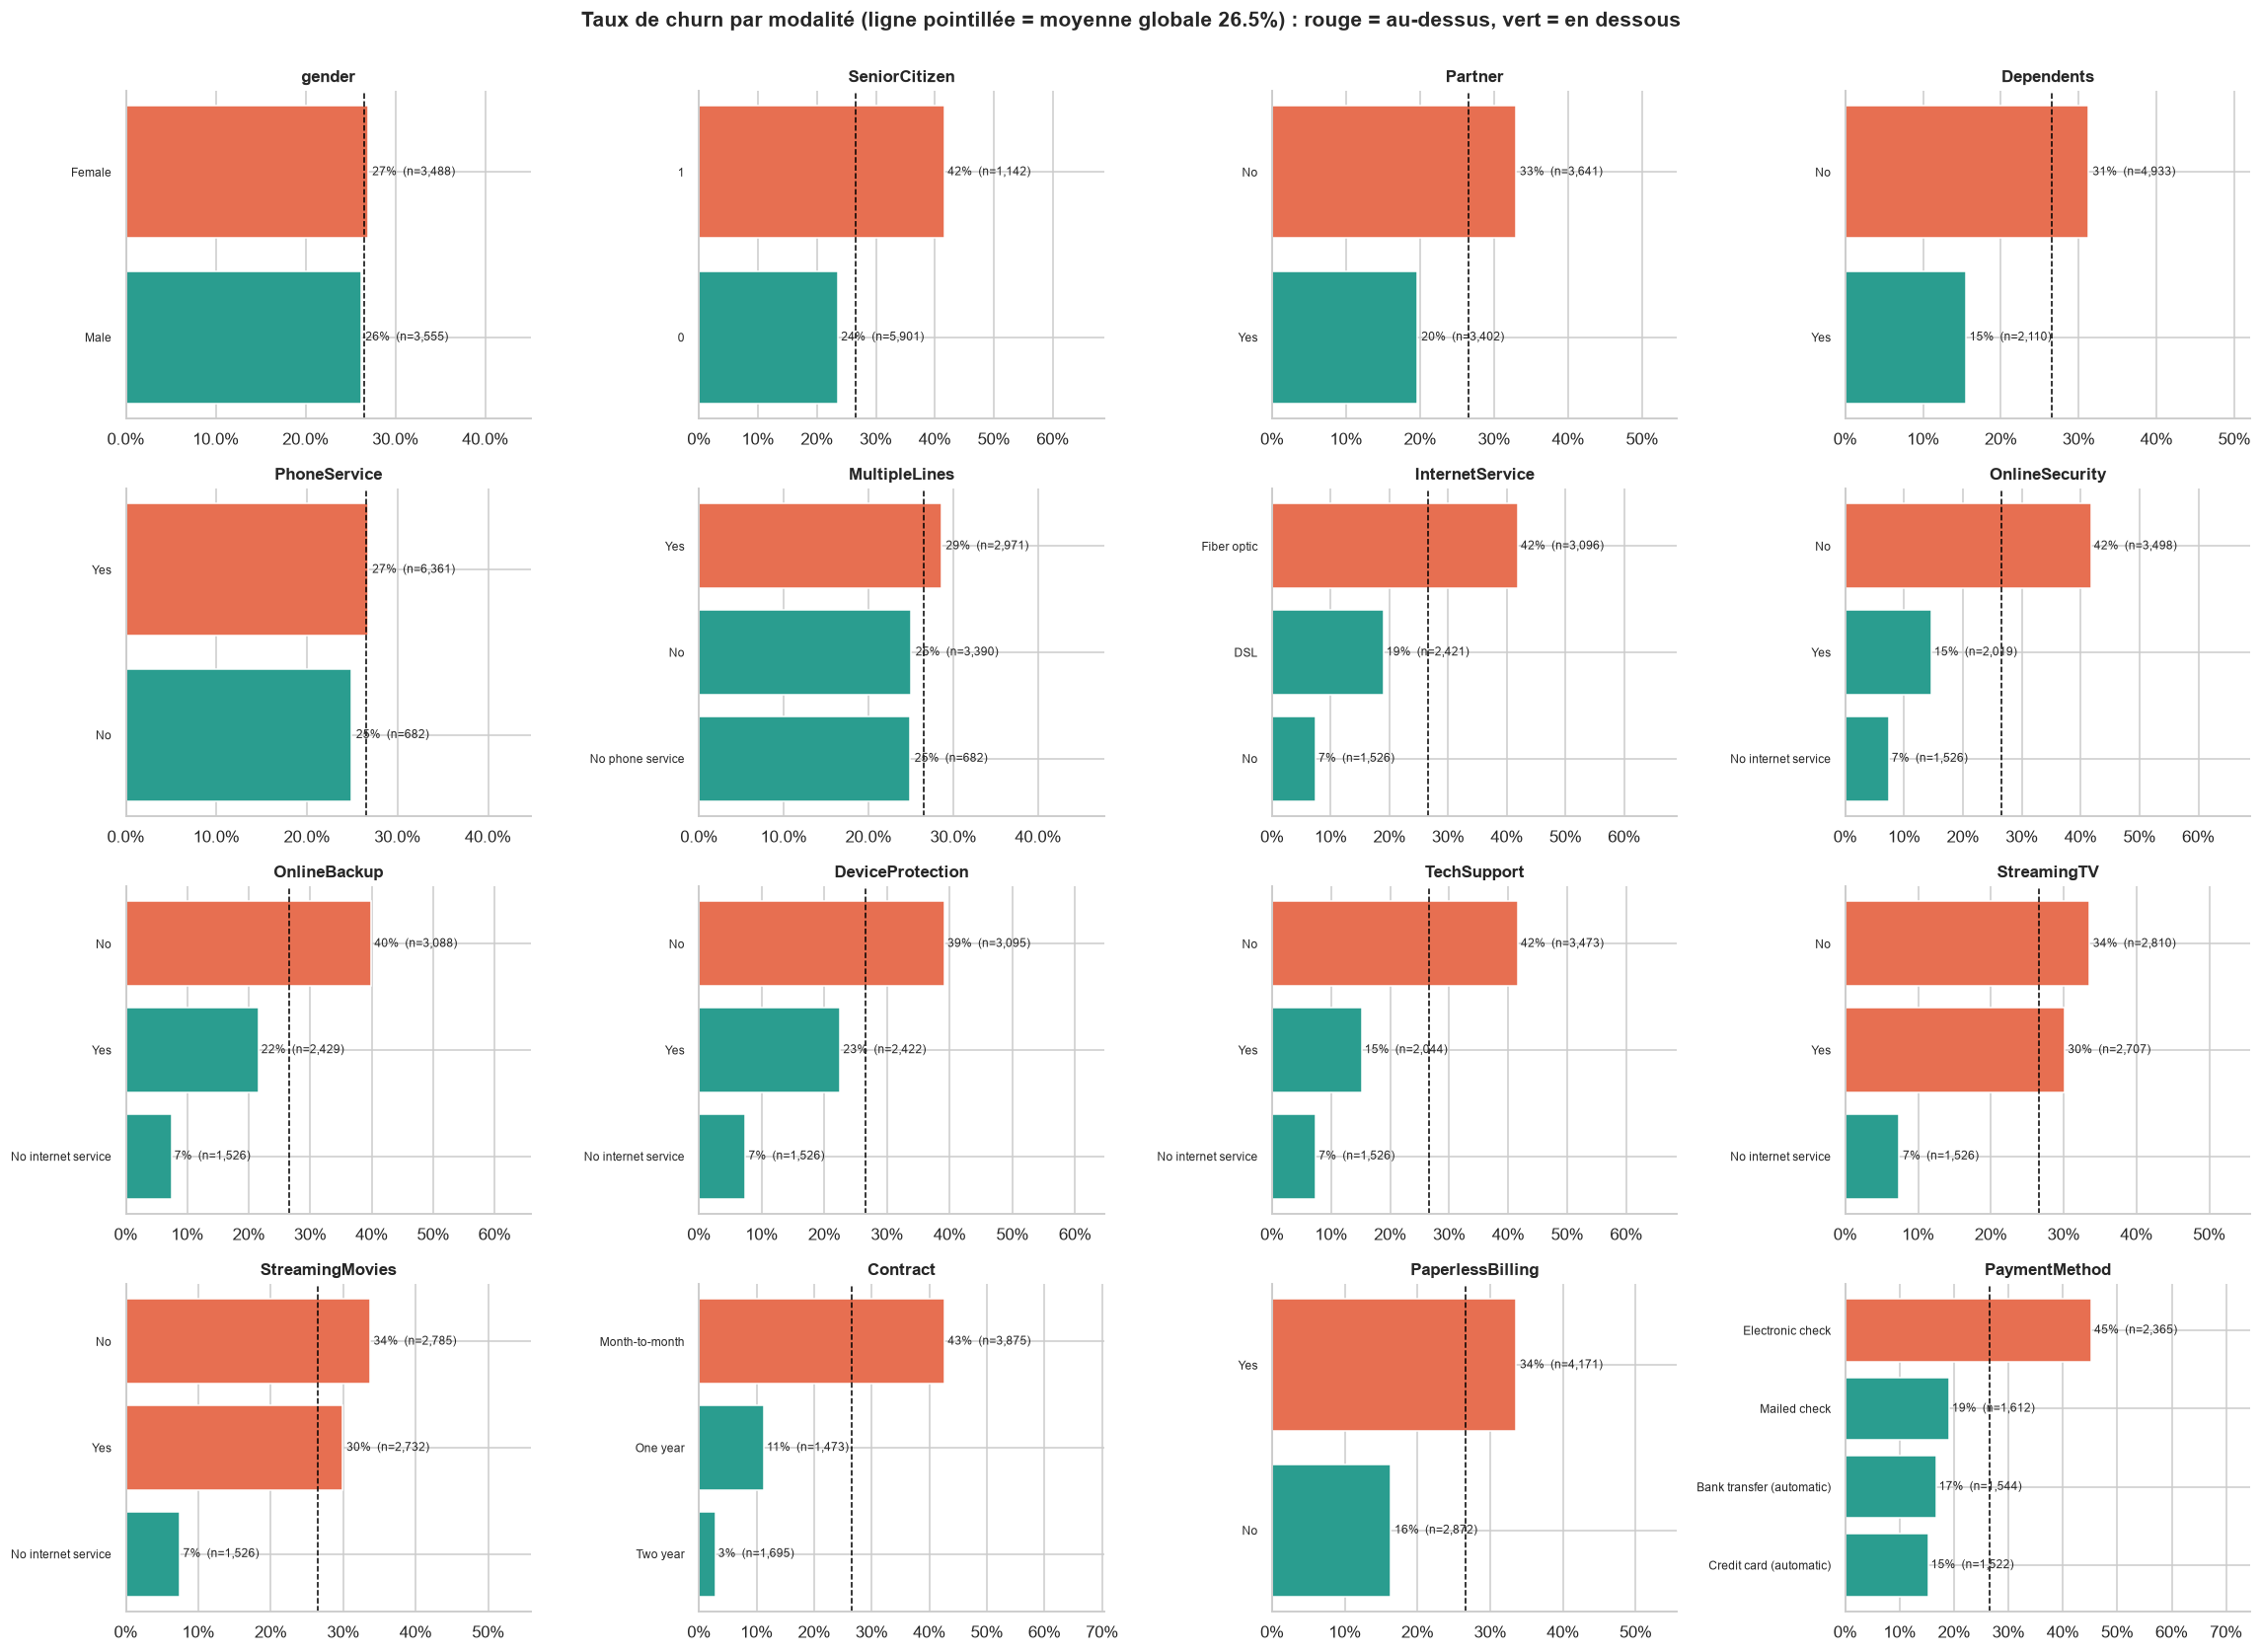

In [26]:
ncols = 4
nrows = int(np.ceil(len(CAT) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(21, 3.8 * nrows))
for ax, c in zip(axes.ravel(), CAT):
    g = churn_mask.groupby(df[c]).agg(['mean', 'size']).sort_values('mean')
    ax.barh(g.index.astype(str), g['mean'], color=[C_CHURN if r > overall_rate else C_STAY for r in g['mean']])
    ax.axvline(overall_rate, color='black', ls='--', lw=1)
    for i, (r, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(r + .005, i, f'{r:.0%}  (n={n:,})', va='center', fontsize=8)
    ax.set_xlim(0, min(1.0, g['mean'].max() * 1.6 + .02)); ax.set_title(c, fontsize=11)
    ax.tick_params(axis='y', labelsize=8); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for ax in axes.ravel()[len(CAT):]:
    ax.axis('off')
fig.suptitle(f'Taux de churn par modalité (ligne pointillée = moyenne globale {overall_rate:.1%}) : rouge = au-dessus, vert = en dessous',
             fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

In [27]:
h('### 6.2 Tableau complet : taux de churn, lift et intervalle de confiance par modalité')
rows = []
for c in CAT:
    g = churn_mask.groupby(df[c]).agg(['sum', 'size'])
    for mod, r in g.iterrows():
        lo, hi = wilson(r['sum'], r['size'])
        rows.append({'variable': c, 'modalité': str(mod), 'clients': int(r['size']), 'churners': int(r['sum']),
                     'taux churn': r['sum'] / r['size'], 'lift vs global': (r['sum'] / r['size']) / overall_rate,
                     'IC95 bas': lo, 'IC95 haut': hi})
mod_table = pd.DataFrame(rows).sort_values('taux churn', ascending=False).reset_index(drop=True)
h('**Top 15 des modalités les plus à risque**')
display(mod_table.head(15))
h('**Top 15 des modalités les plus protectrices**')
display(mod_table.tail(15).iloc[::-1])

### 6.2 Tableau complet : taux de churn, lift et intervalle de confiance par modalité

**Top 15 des modalités les plus à risque**

,variable,modalité,clients,churners,taux churn,lift vs global,IC95 bas,IC95 haut
0,PaymentMethod,Electronic check,2365,1071,0.453,1.707,0.433,0.473
1,Contract,Month-to-month,3875,1655,0.427,1.609,0.412,0.443
2,InternetService,Fiber optic,3096,1297,0.419,1.579,0.402,0.436
3,OnlineSecurity,No,3498,1461,0.418,1.574,0.401,0.434
4,SeniorCitizen,1,1142,476,0.417,1.571,0.389,0.446
5,TechSupport,No,3473,1446,0.416,1.569,0.400,0.433
6,OnlineBackup,No,3088,1233,0.399,1.505,0.382,0.417
7,DeviceProtection,No,3095,1211,0.391,1.474,0.374,0.409
8,StreamingMovies,No,2785,938,0.337,1.269,0.319,0.355
9,PaperlessBilling,Yes,4171,1400,0.336,1.265,0.321,0.350


**Top 15 des modalités les plus protectrices**

,variable,modalité,clients,churners,taux churn,lift vs global,IC95 bas,IC95 haut
42,Contract,Two year,1695,48,0.028,0.107,0.021,0.037
41,StreamingMovies,No internet service,1526,113,0.074,0.279,0.062,0.088
40,StreamingTV,No internet service,1526,113,0.074,0.279,0.062,0.088
39,InternetService,No,1526,113,0.074,0.279,0.062,0.088
38,OnlineSecurity,No internet service,1526,113,0.074,0.279,0.062,0.088
37,OnlineBackup,No internet service,1526,113,0.074,0.279,0.062,0.088
36,DeviceProtection,No internet service,1526,113,0.074,0.279,0.062,0.088
35,TechSupport,No internet service,1526,113,0.074,0.279,0.062,0.088
34,Contract,One year,1473,166,0.113,0.425,0.098,0.130
33,OnlineSecurity,Yes,2019,295,0.146,0.551,0.131,0.162


### 6.3 Force des associations avec le churn : V de Cramér, chi², p-value

,variable,V de Cramér,chi²,p-value,force du lien
0,Contract,0.410,"1,184.597",0.000,forte
1,OnlineSecurity,0.347,849.999,0.000,forte
2,TechSupport,0.343,828.197,0.000,forte
3,InternetService,0.322,732.310,0.000,forte
4,PaymentMethod,0.303,648.142,0.000,forte
5,OnlineBackup,0.292,601.813,0.000,modérée
6,DeviceProtection,0.281,558.419,0.000,modérée
7,StreamingMovies,0.230,375.661,0.000,modérée
8,StreamingTV,0.230,374.204,0.000,modérée
9,PaperlessBilling,0.191,259.161,0.000,faible


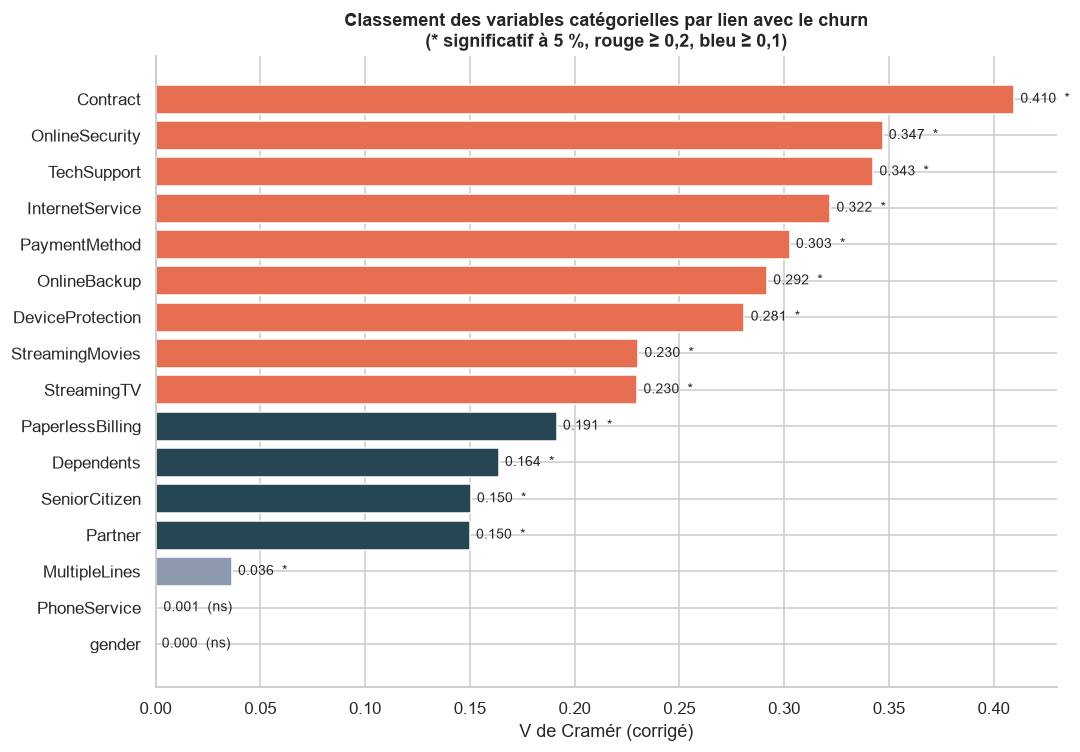

In [28]:
h('### 6.3 Force des associations avec le churn : V de Cramér, chi², p-value')
rows = []
for c in CAT:
    v, chi2, p = cramers_v(df[c], df[TARGET])
    rows.append({'variable': c, 'V de Cramér': v, 'chi²': chi2, 'p-value': p, 'force du lien': strength(v)})
assoc = pd.DataFrame(rows).sort_values('V de Cramér', ascending=False).reset_index(drop=True)
display(assoc)

fig, ax = plt.subplots(figsize=(10, 7))
a = assoc.sort_values('V de Cramér')
ax.barh(a['variable'], a['V de Cramér'], color=[C_CHURN if v >= .2 else C_MAIN if v >= .1 else C_GREY for v in a['V de Cramér']])
for i, (v, p) in enumerate(zip(a['V de Cramér'], a['p-value'])):
    ax.text(v + .003, i, f'{v:.3f}' + ('  *' if p < .05 else '  (ns)'), va='center', fontsize=9)
ax.set_title('Classement des variables catégorielles par lien avec le churn\n(* significatif à 5 %, rouge ≥ 0,2, bleu ≥ 0,1)')
ax.set_xlabel('V de Cramér (corrigé)'); plt.tight_layout(); plt.show()

### 6.4 Les trois leviers contractuels en barres 100 % empilées

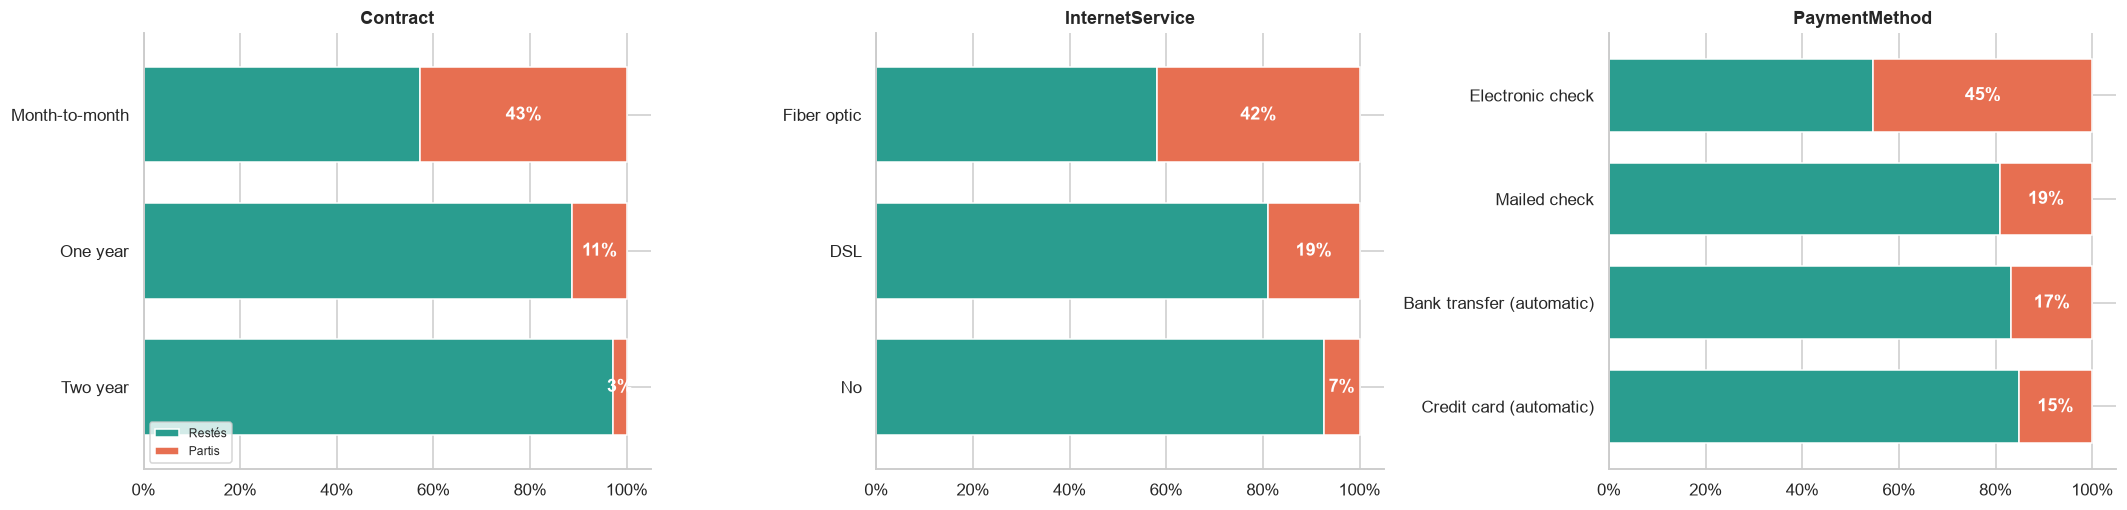

In [29]:
h('### 6.4 Les trois leviers contractuels en barres 100 % empilées')
top3 = [c for c in ['Contract', 'InternetService', 'PaymentMethod'] if c in df.columns]
fig, axes = plt.subplots(1, len(top3), figsize=(6.5 * len(top3), 4.8))
for ax, c in zip(np.atleast_1d(axes), top3):
    ct = pd.crosstab(df[c], df[TARGET], normalize='index')[['No', 'Yes']]
    ct = ct.sort_values('Yes')
    ct.plot(kind='barh', stacked=True, color=[C_STAY, C_CHURN], ax=ax, legend=False, width=.7)
    for i, (idx, r) in enumerate(ct.iterrows()):
        ax.text(r['No'] + r['Yes'] / 2, i, f"{r['Yes']:.0%}", ha='center', va='center', color='white', fontweight='bold')
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel(''); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
np.atleast_1d(axes)[0].legend(['Restés', 'Partis'], loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

---
## 7. Variables numériques vs Churn
**Objectif :** comparer le profil des clients partis et restés, mesurer la taille d'effet, et suivre le churn le long de l'ancienneté et du prix.

In [30]:
h('### 7.1 Statistiques comparées par groupe')
rows = []
for name, s in num_views.items():
    for grp, m in [('Restés', ~churn_mask), ('Partis', churn_mask)]:
        x = s[m].dropna()
        rows.append({'variable': name, 'groupe': grp, 'n': len(x), 'moyenne': x.mean(), 'médiane': x.median(),
                     'écart-type': x.std(), 'Q1': x.quantile(.25), 'Q3': x.quantile(.75)})
display(pd.DataFrame(rows).set_index(['variable', 'groupe']))

h('### 7.2 Tests statistiques et tailles d\'effet')
rows = []
for name, s in num_views.items():
    a, b = s[churn_mask].dropna(), s[~churn_mask].dropna()
    u, p_mw = stats.mannwhitneyu(a, b, alternative='two-sided')
    t, p_t = stats.ttest_ind(a, b, equal_var=False)
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    d = (a.mean() - b.mean()) / pooled
    rbc = 2 * u / (len(a) * len(b)) - 1
    rows.append({'variable': name, 'Δ médiane (partis − restés)': a.median() - b.median(),
                 'Mann-Whitney p': p_mw, 'Welch t p': p_t, "d de Cohen": d, 'taille d\'effet': effect_label(d),
                 'rang-bisérial': rbc})
tests = pd.DataFrame(rows).set_index('variable')
display(tests)
print('Cohen d < 0 : les partis ont des valeurs plus faibles ; rang-bisérial : proba que un parti soit au-dessus d\'un resté, recentrée.')

### 7.1 Statistiques comparées par groupe

n   moyenne   médiane  écart-type      Q1        Q3
variable            groupe                                                        
tenure              Restés  5174    37.570    38.000      24.114  15.000    61.000
                    Partis  1869    17.979    10.000      19.531   2.000    29.000
MonthlyCharges      Restés  5174    61.265    64.425      31.093  25.100    88.400
                    Partis  1869    74.441    79.650      24.666  56.150    94.200
TotalCharges (num.) Restés  5163 2,555.344 1,683.600   2,329.457 577.825 4,264.125
                    Partis  1869 1,531.796   703.550   1,890.823 134.500 2,331.300

### 7.2 Tests statistiques et tailles d'effet

,Δ médiane (partis − restés),Mann-Whitney p,Welch t p,d de Cohen,taille d'effet,rang-bisérial
variable,,,,,,
tenure,-28.000,0.000,0.000,-0.852,grand,-0.480
MonthlyCharges,15.225,0.000,0.000,0.446,petit,0.242
TotalCharges (num.),-980.050,0.000,0.000,-0.461,petit,-0.303


Cohen d < 0 : les partis ont des valeurs plus faibles ; rang-bisérial : proba que un parti soit au-dessus d'un resté, recentrée.


### 7.3 Distributions comparées (densité, boxplot, violon, ECDF)

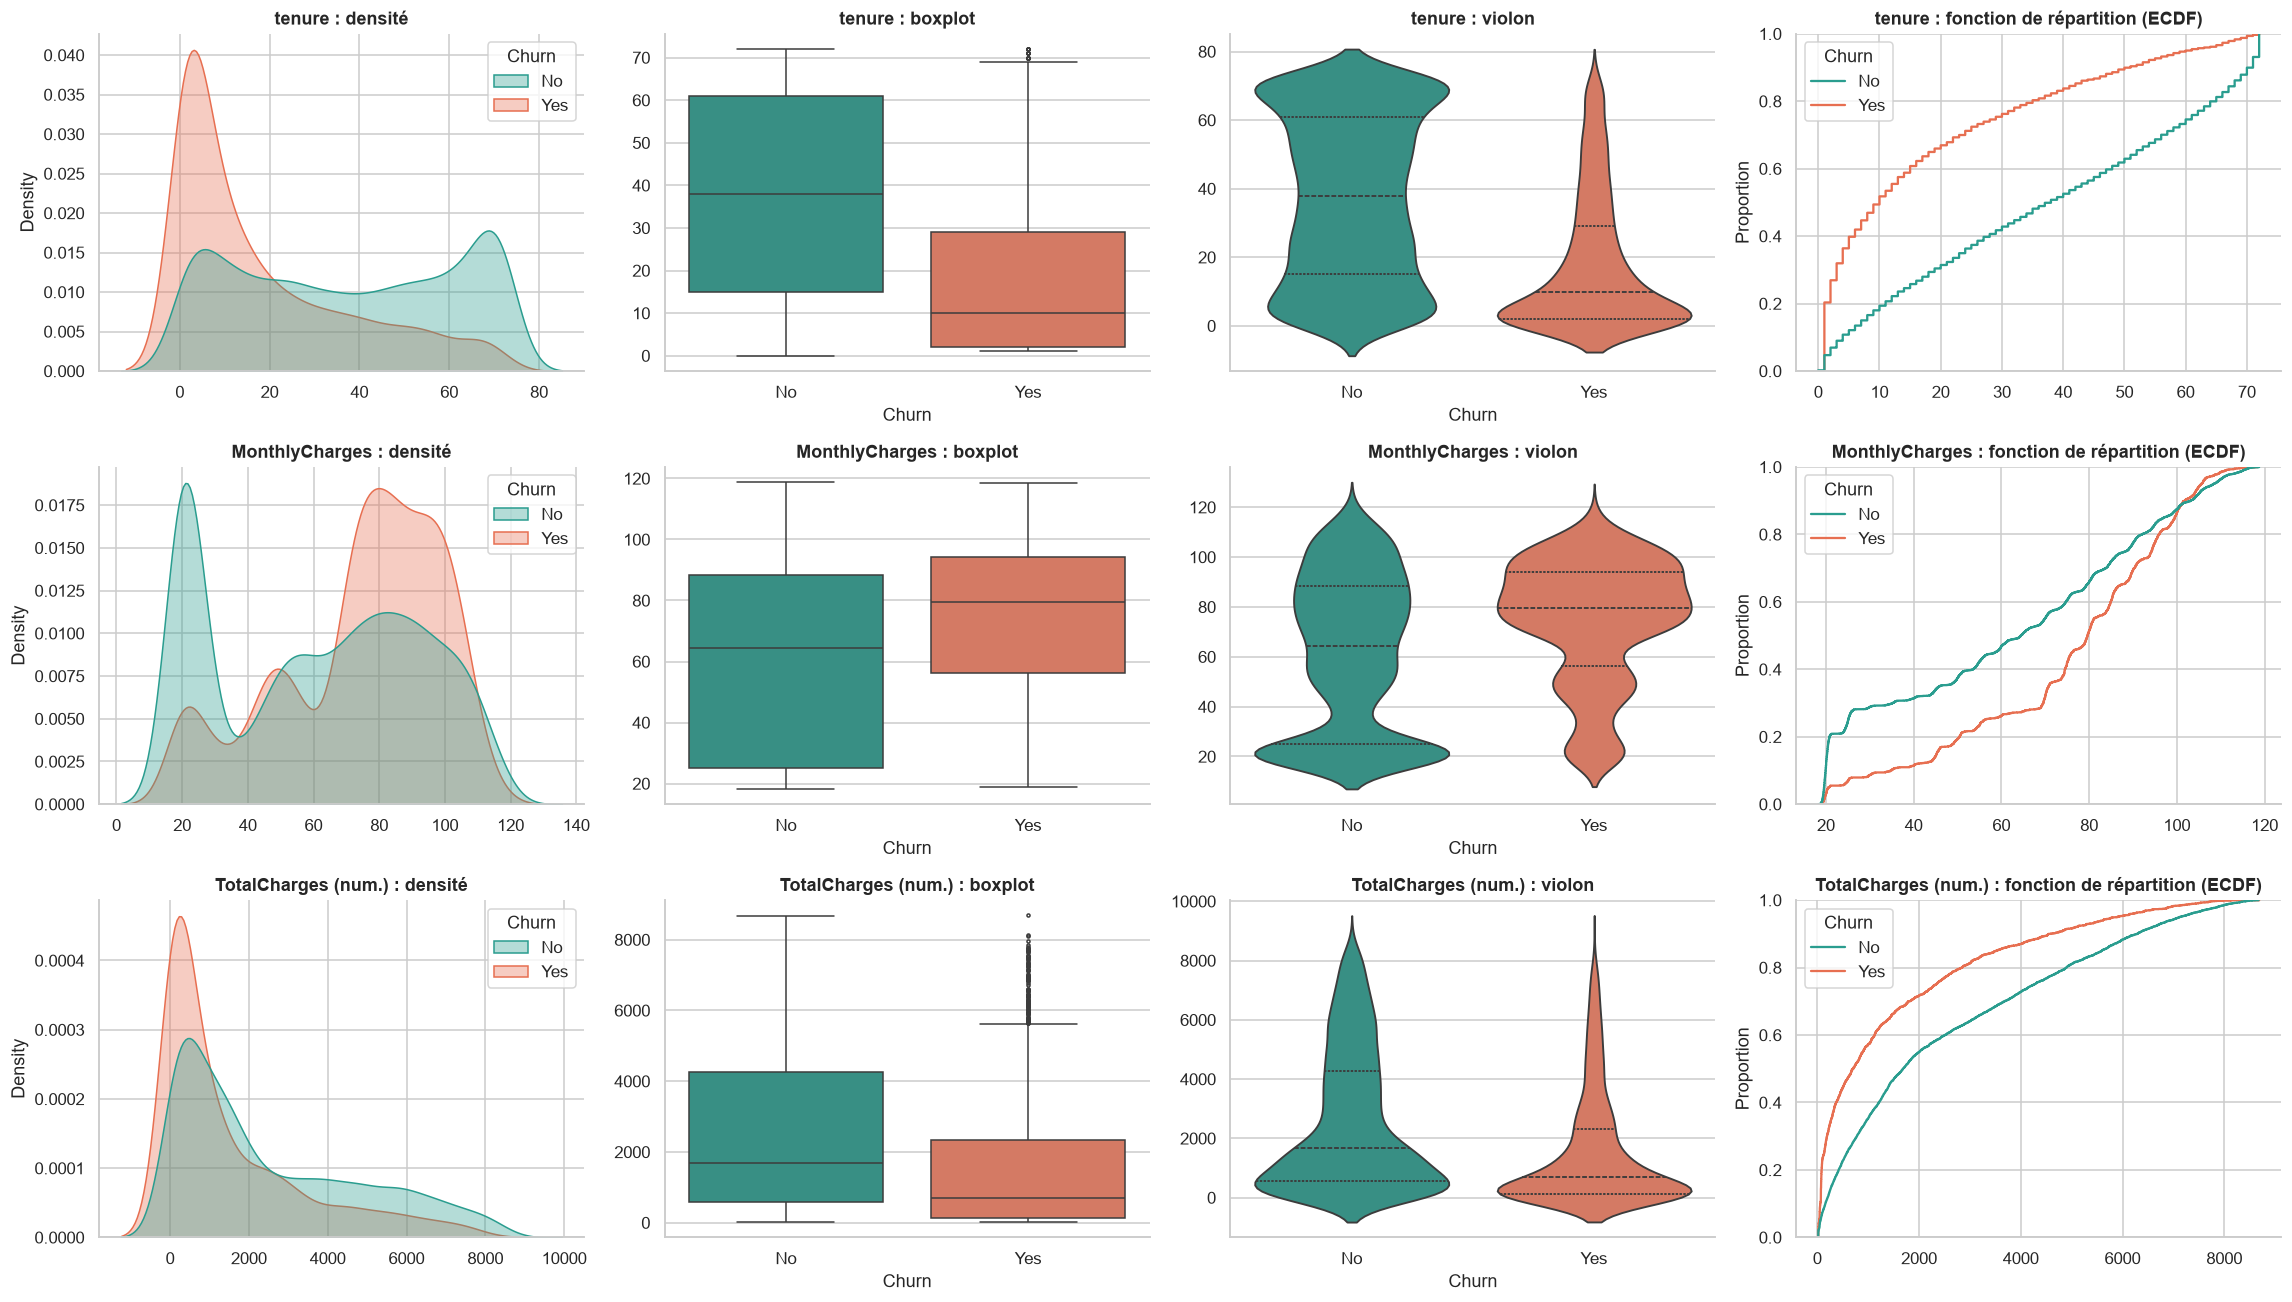

In [31]:
h('### 7.3 Distributions comparées (densité, boxplot, violon, ECDF)')
fig, axes = plt.subplots(3, 4, figsize=(21, 12))
for i, (name, s) in enumerate(num_views.items()):
    d = pd.DataFrame({'v': s, 'Churn': df[TARGET]}).dropna()
    sns.kdeplot(data=d, x='v', hue='Churn', palette=PALETTE, fill=True, common_norm=False, alpha=.35, ax=axes[i, 0])
    axes[i, 0].set_title(f'{name} : densité'); axes[i, 0].set_xlabel('')
    sns.boxplot(data=d, x='Churn', y='v', palette=PALETTE, hue='Churn', legend=False, order=['No', 'Yes'], ax=axes[i, 1], fliersize=2)
    axes[i, 1].set_title(f'{name} : boxplot'); axes[i, 1].set_ylabel('')
    sns.violinplot(data=d, x='Churn', y='v', palette=PALETTE, hue='Churn', legend=False, order=['No', 'Yes'], inner='quartile', ax=axes[i, 2])
    axes[i, 2].set_title(f'{name} : violon'); axes[i, 2].set_ylabel('')
    sns.ecdfplot(data=d, x='v', hue='Churn', palette=PALETTE, ax=axes[i, 3])
    axes[i, 3].set_title(f'{name} : fonction de répartition (ECDF)'); axes[i, 3].set_xlabel('')
plt.tight_layout(); plt.show()

### 7.4 Le churn le long de l'ancienneté (mois par mois, sans créer de tranches)

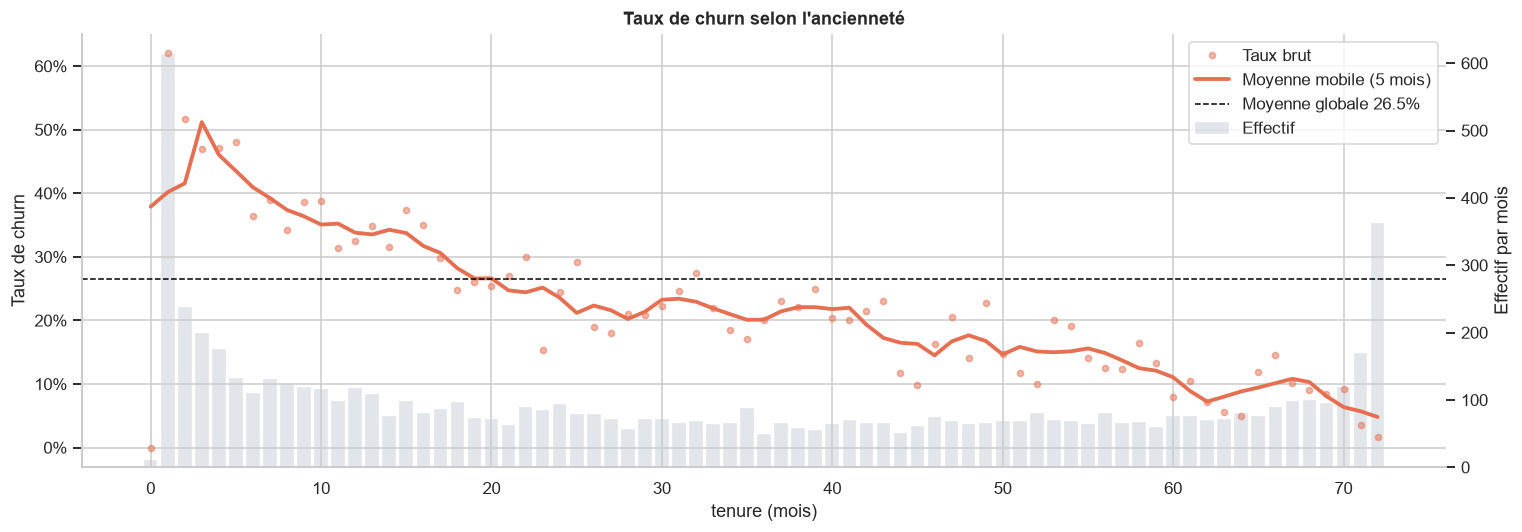

Churn des clients avec tenure ≤ 12 mois : 47.4%   |   > 12 mois : 17.1%


In [32]:
h('### 7.4 Le churn le long de l\'ancienneté (mois par mois, sans créer de tranches)')
g = churn_mask.groupby(df['tenure']).agg(['mean', 'size'])
g['lisse'] = g['mean'].rolling(5, center=True, min_periods=2).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax2 = ax.twinx()
ax2.bar(g.index, g['size'], color=C_GREY, alpha=.25, label='Effectif')
ax2.set_ylabel('Effectif par mois'); ax2.grid(False)
ax.plot(g.index, g['mean'], 'o', color=C_CHURN, alpha=.5, ms=4, label='Taux brut')
ax.plot(g.index, g['lisse'], '-', color=C_CHURN, lw=2.5, label='Moyenne mobile (5 mois)')
ax.axhline(overall_rate, color='black', ls='--', lw=1, label=f'Moyenne globale {overall_rate:.1%}')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('tenure (mois)'); ax.set_ylabel('Taux de churn'); ax.set_title('Taux de churn selon l\'ancienneté')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right'); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
plt.tight_layout(); plt.show()

early = churn_mask[df['tenure'] <= 12].mean(); late = churn_mask[df['tenure'] > 12].mean()
print(f'Churn des clients avec tenure ≤ 12 mois : {early:.1%}   |   > 12 mois : {late:.1%}')

### 7.5 Le churn selon le prix et la facturation cumulée (courbes glissantes)

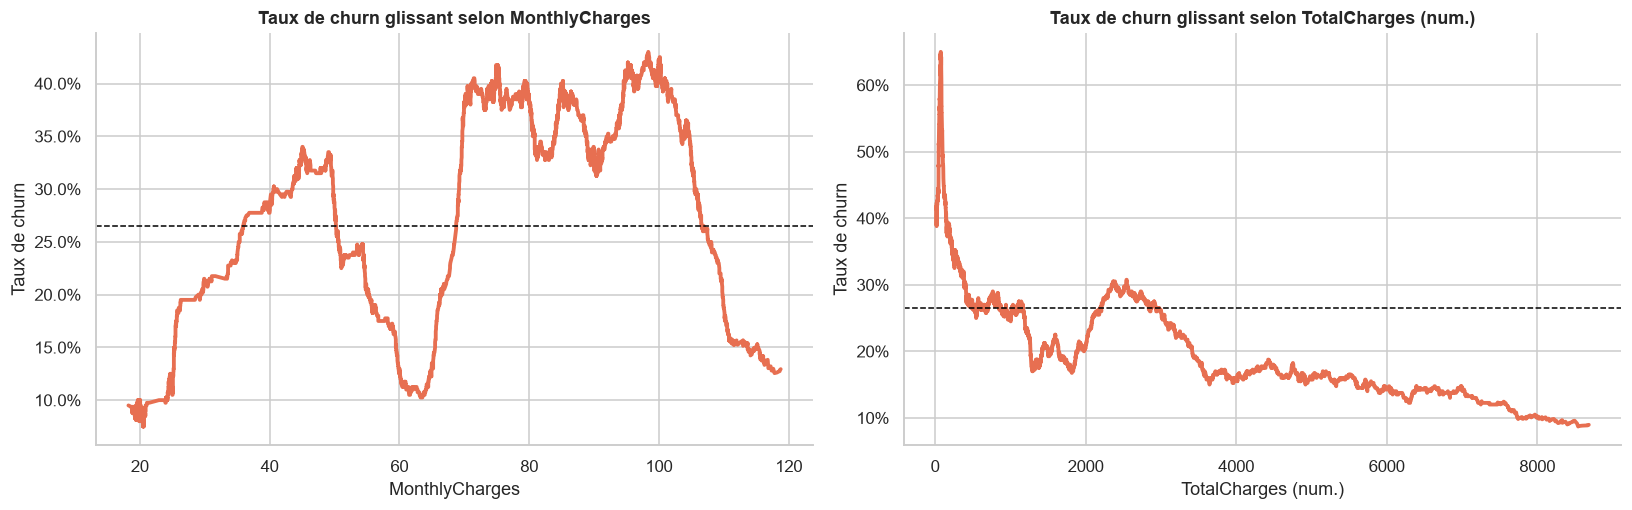

In [33]:
h('### 7.5 Le churn selon le prix et la facturation cumulée (courbes glissantes)')
def rolling_rate(values, mask, window):
    d = pd.DataFrame({'x': values, 'y': mask.astype(float)}).dropna().sort_values('x')
    d['r'] = d['y'].rolling(window, center=True, min_periods=window // 2).mean()
    return d['x'].values, d['r'].values

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for a, (name, s, w) in zip(ax, [('MonthlyCharges', df['MonthlyCharges'], 400), ('TotalCharges (num.)', total_charges, 400)]):
    x, r = rolling_rate(s, churn_mask, w)
    a.plot(x, r, color=C_CHURN, lw=2.5)
    a.axhline(overall_rate, color='black', ls='--', lw=1)
    a.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    a.set_title(f'Taux de churn glissant selon {name}'); a.set_xlabel(name); a.set_ylabel('Taux de churn')
plt.tight_layout(); plt.show()

---
## 8. Analyse multivariée
**Objectif :** relations entre variables (multicolinéarité), interactions entre deux facteurs, structure globale.

### 8.1 Corrélations entre variables numériques (Pearson et Spearman)

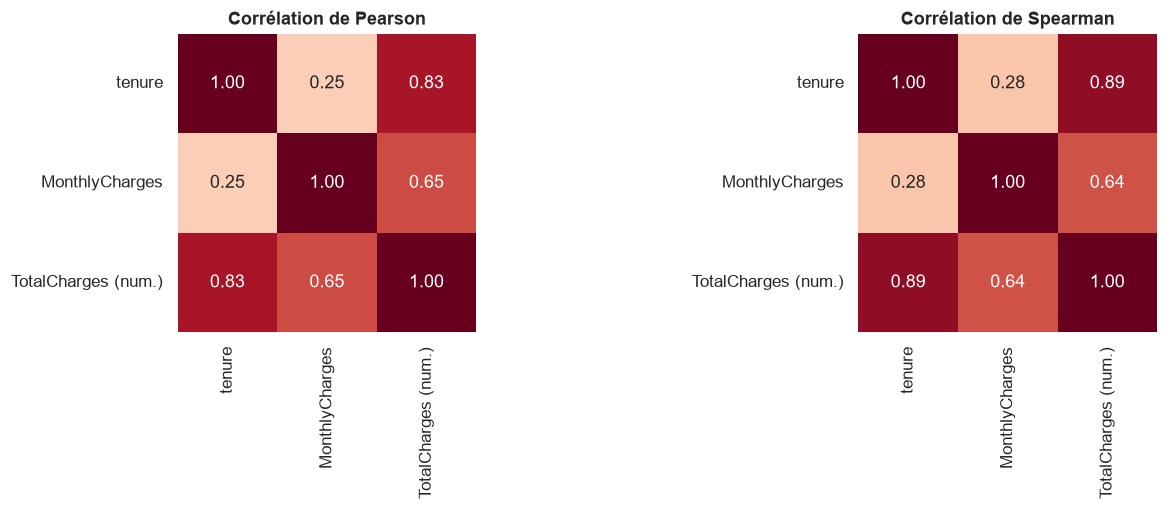

Corrélation tenure ↔ TotalCharges = 0.83 : forte redondance, à garder en tête pour la modélisation (multicolinéarité).


In [34]:
h('### 8.1 Corrélations entre variables numériques (Pearson et Spearman)')
num_view = pd.DataFrame({'tenure': df['tenure'], 'MonthlyCharges': df['MonthlyCharges'], 'TotalCharges (num.)': total_charges})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, m in zip(ax, ['pearson', 'spearman']):
    sns.heatmap(num_view.corr(method=m), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=a, cbar=False)
    a.set_title(f'Corrélation de {m.capitalize()}')
plt.tight_layout(); plt.show()
cr = num_view.corr().loc['tenure', 'TotalCharges (num.)']
print(f'Corrélation tenure ↔ TotalCharges = {cr:.2f} : forte redondance, à garder en tête pour la modélisation (multicolinéarité).')

### 8.2 Nuage de points et pairplot, colorés par churn

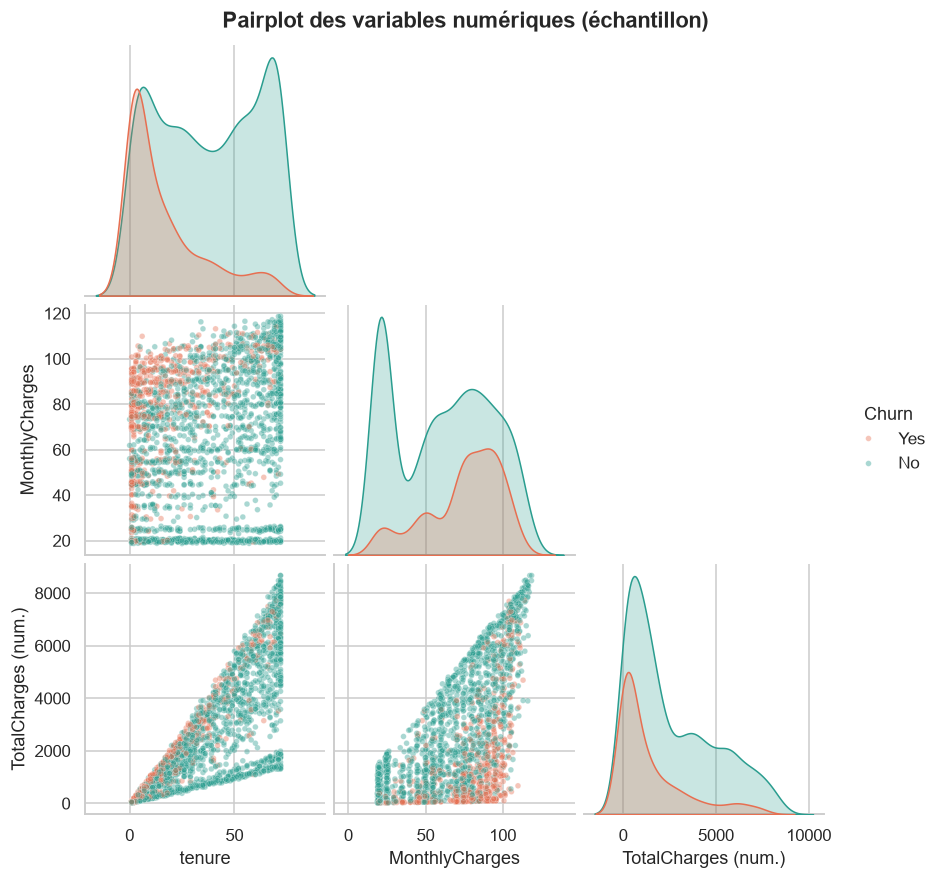

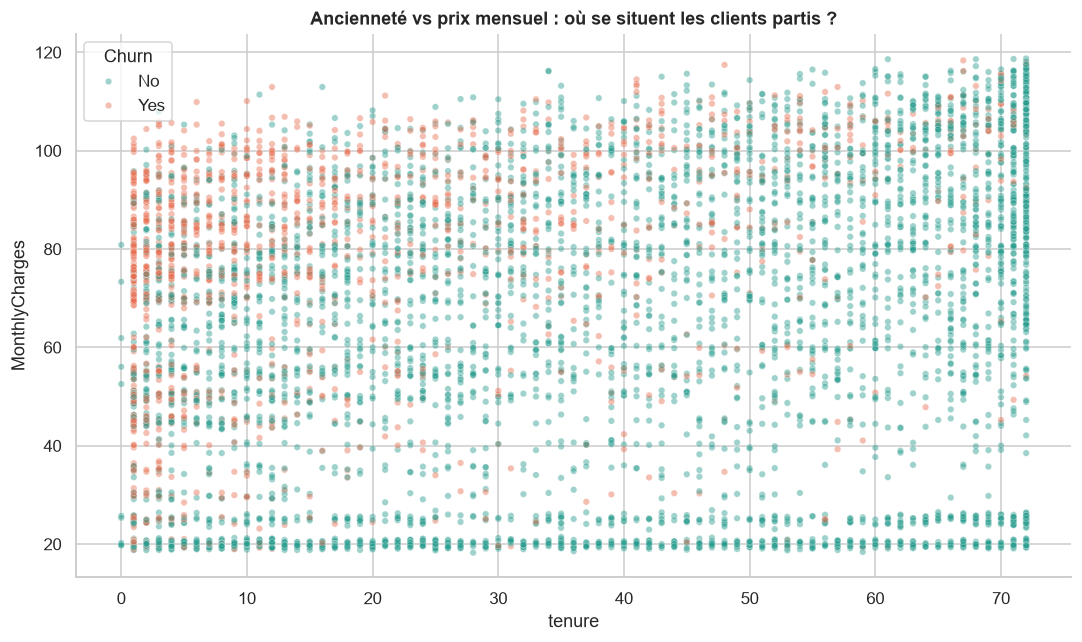

In [35]:
h('### 8.2 Nuage de points et pairplot, colorés par churn')
samp = num_view.assign(Churn=df[TARGET]).sample(min(2500, len(df)), random_state=42)
g = sns.pairplot(samp, hue='Churn', palette=PALETTE, corner=True, plot_kws=dict(alpha=.4, s=14), diag_kind='kde', height=2.6)
g.figure.suptitle('Pairplot des variables numériques (échantillon)', y=1.02, fontweight='bold')
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x=df['tenure'], y=df['MonthlyCharges'], hue=df[TARGET], palette=PALETTE, alpha=.45, s=18, ax=ax)
ax.set_title('Ancienneté vs prix mensuel : où se situent les clients partis ?')
plt.tight_layout(); plt.show()

### 8.3 Matrice des associations entre toutes les variables catégorielles (V de Cramér)

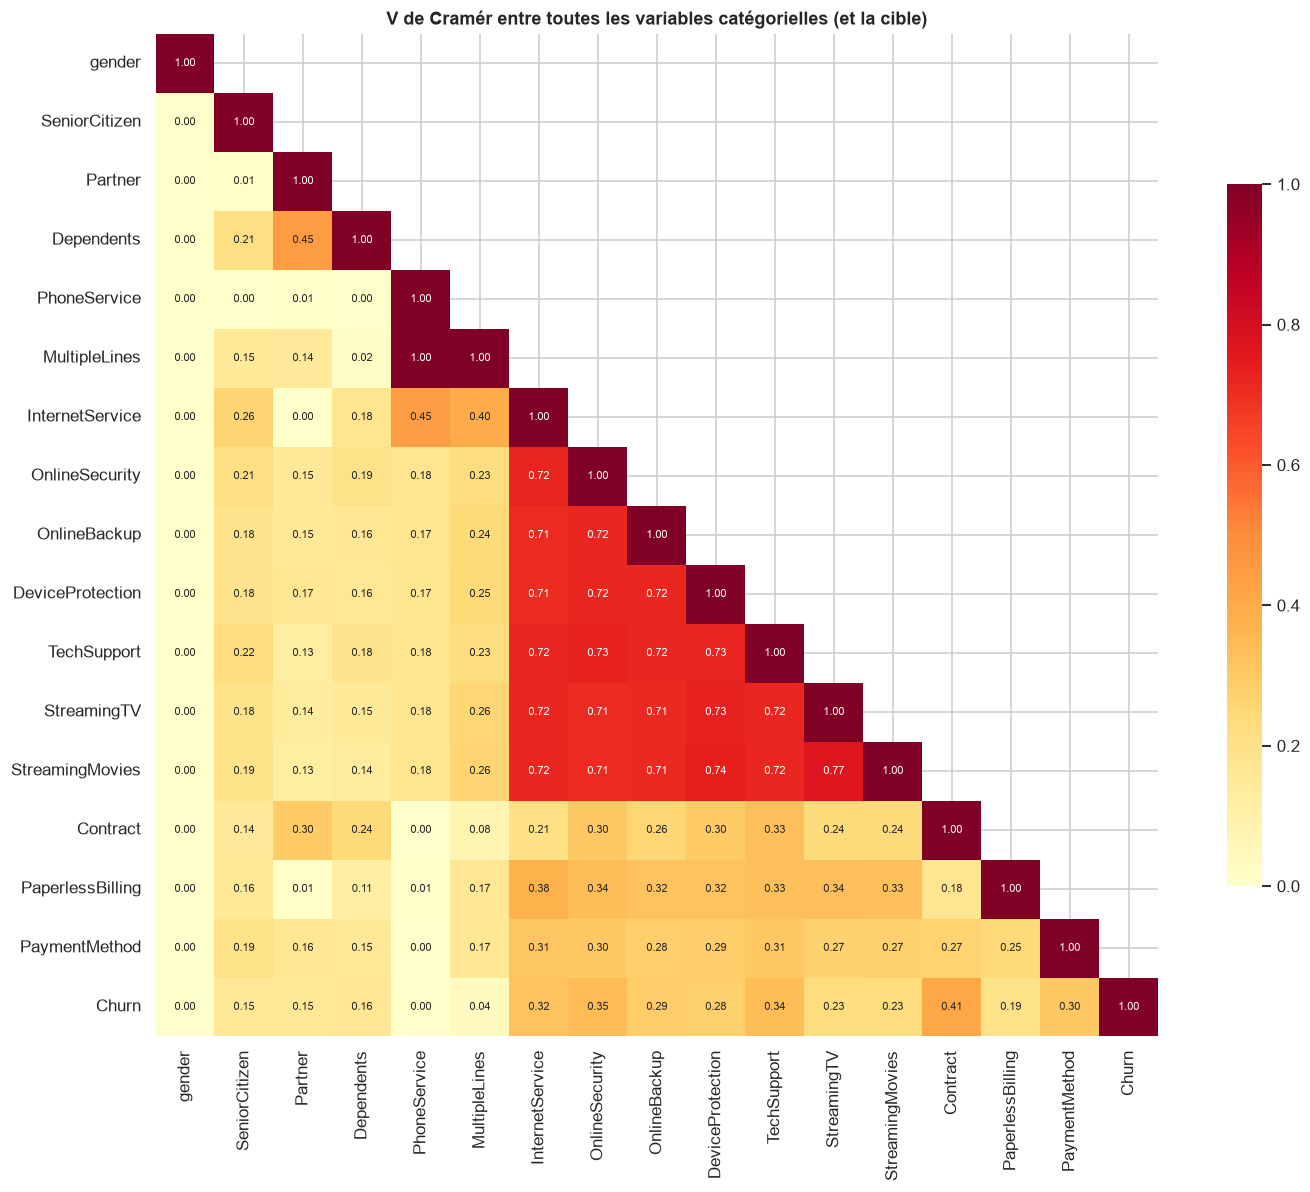

**Paires de variables les plus liées (redondance potentielle)**

V de Cramér
MultipleLines    PhoneService            1.000
StreamingMovies  StreamingTV             0.771
                 DeviceProtection        0.736
StreamingTV      DeviceProtection        0.734
TechSupport      OnlineSecurity          0.733
                 DeviceProtection        0.726
OnlineSecurity   InternetService         0.724
TechSupport      InternetService         0.723
                 OnlineBackup            0.720
DeviceProtection OnlineBackup            0.719
OnlineBackup     OnlineSecurity          0.718
DeviceProtection OnlineSecurity          0.717

In [36]:
h('### 8.3 Matrice des associations entre toutes les variables catégorielles (V de Cramér)')
vars_all = CAT + [TARGET]
V = pd.DataFrame(np.nan, index=vars_all, columns=vars_all)
for i, a in enumerate(vars_all):
    for b in vars_all[i:]:
        v = 1.0 if a == b else cramers_v(df[a], df[b])[0]
        V.loc[a, b] = V.loc[b, a] = v
mask_up = np.triu(np.ones_like(V, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(V.astype(float), mask=mask_up, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='YlOrRd', vmin=0, vmax=1, square=True,
            cbar_kws={'shrink': .7}, ax=ax)
ax.set_title('V de Cramér entre toutes les variables catégorielles (et la cible)')
plt.tight_layout(); plt.show()

pairs = (V.where(~mask_up & ~np.eye(len(V), dtype=bool)).stack().sort_values(ascending=False))
h('**Paires de variables les plus liées (redondance potentielle)**')
display(pairs.head(12).rename('V de Cramér').to_frame())

### 8.4 Interactions : taux de churn selon deux facteurs croisés

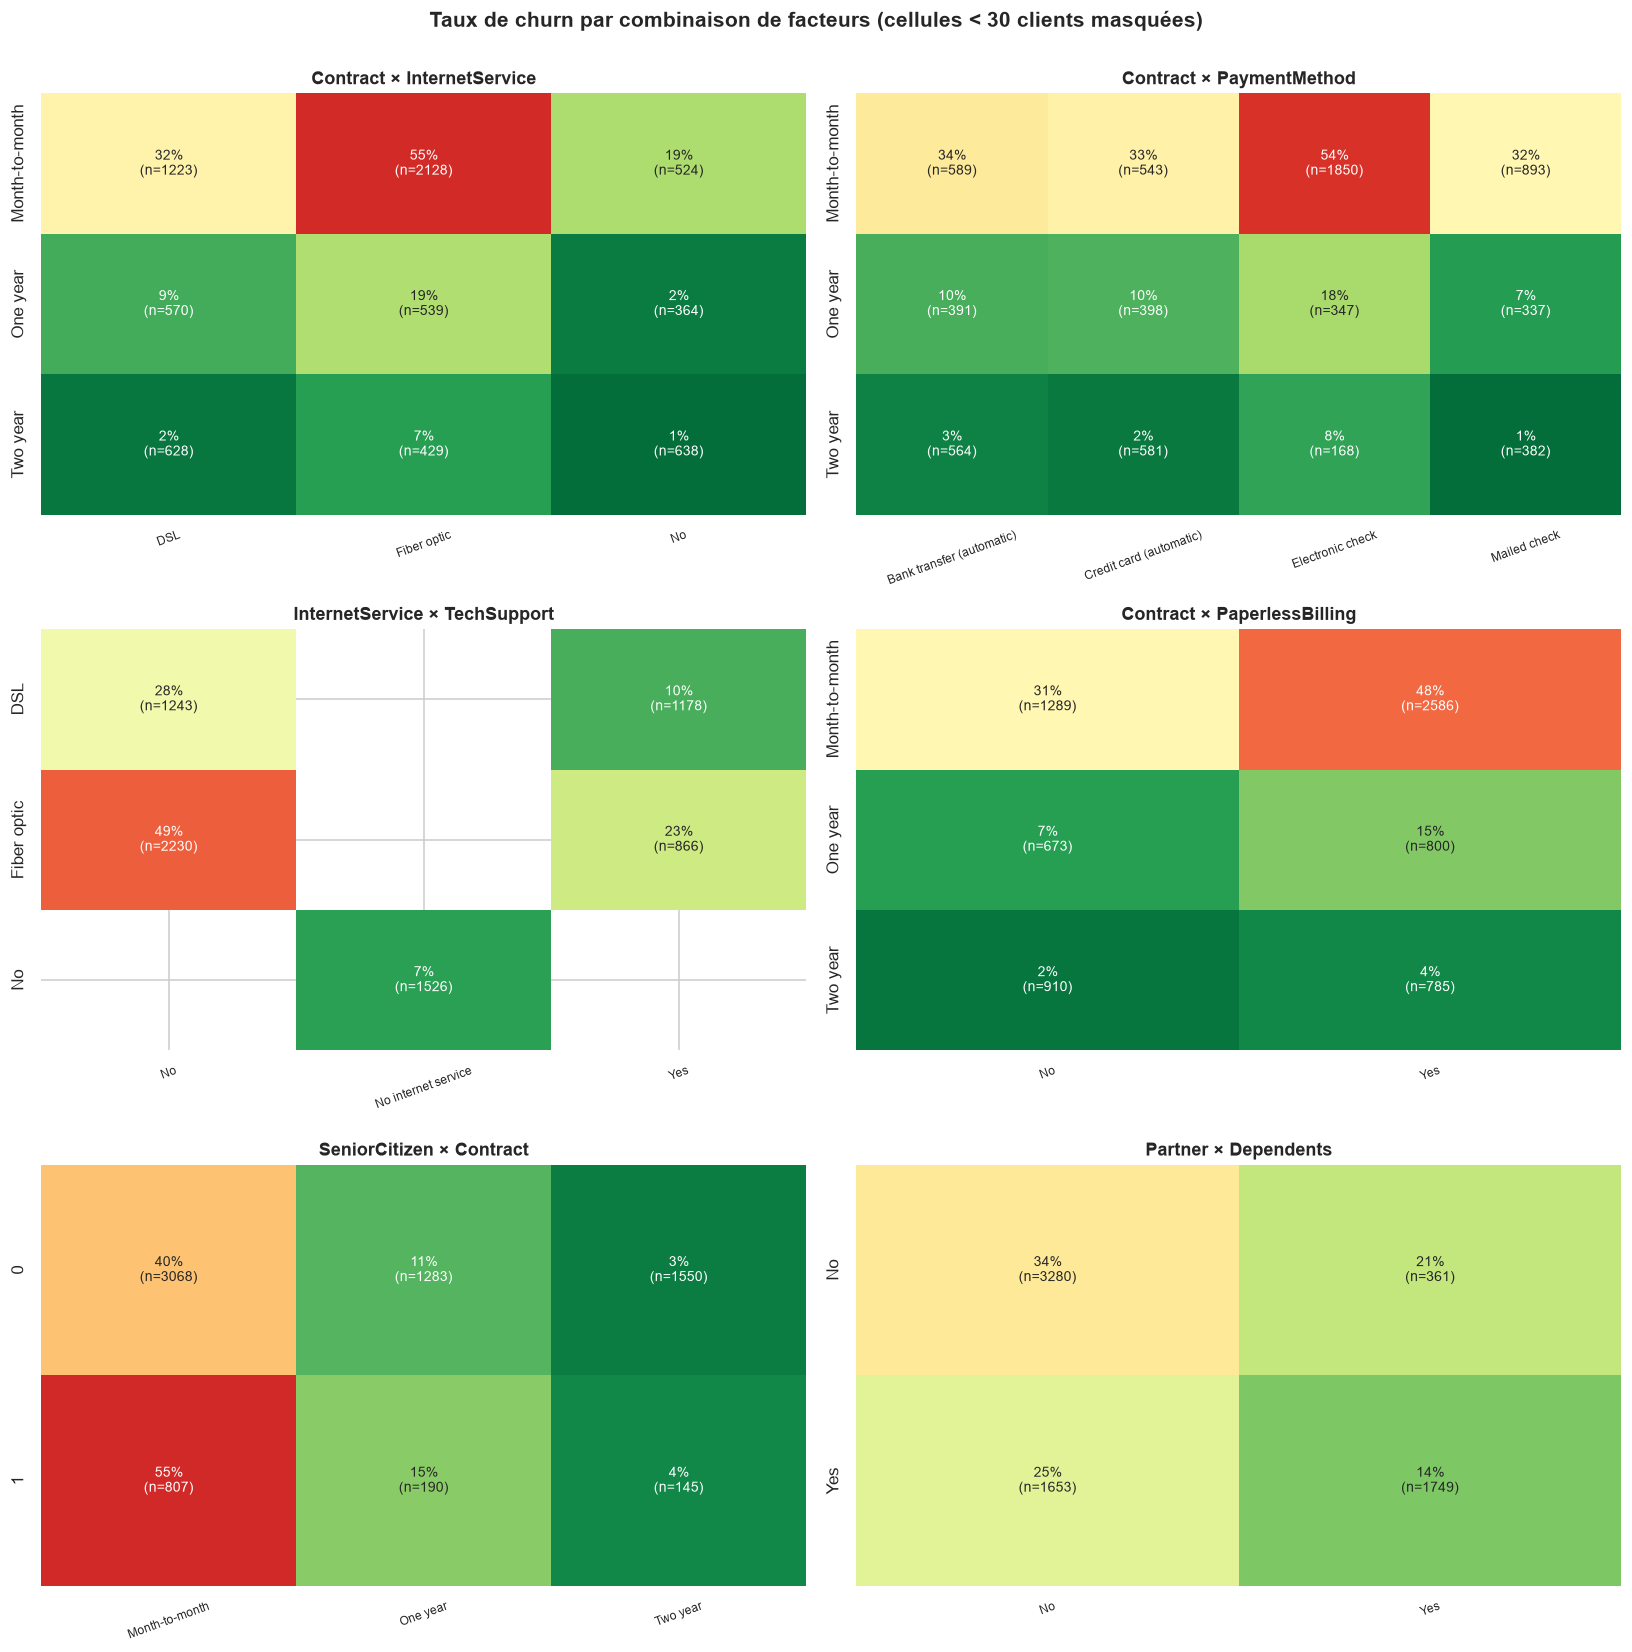

In [37]:
h('### 8.4 Interactions : taux de churn selon deux facteurs croisés')
combos = [('Contract', 'InternetService'), ('Contract', 'PaymentMethod'), ('InternetService', 'TechSupport'),
          ('Contract', 'PaperlessBilling'), ('SeniorCitizen', 'Contract'), ('Partner', 'Dependents')]
combos = [(a, b) for a, b in combos if a in df.columns and b in df.columns]
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
for ax, (a, b) in zip(axes.ravel(), combos):
    rate = pd.crosstab(df[a], df[b], values=churn_mask.astype(float), aggfunc='mean')
    n = pd.crosstab(df[a], df[b])
    rate = rate.where(n >= 30)                         # on masque les cellules < 30 clients (non fiables)
    annot = rate.map(lambda v: '' if pd.isna(v) else f'{v:.0%}') + '\n(n=' + n.astype(str) + ')'
    sns.heatmap(rate, annot=annot, fmt='', cmap='RdYlGn_r', vmin=0, vmax=max(.6, np.nanmax(rate.values)), cbar=False, ax=ax,
                annot_kws={'size': 9})
    ax.set_title(f'{a} × {b}'); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
fig.suptitle('Taux de churn par combinaison de facteurs (cellules < 30 clients masquées)', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

### 8.5 Variables numériques selon les catégories clés, séparées par churn

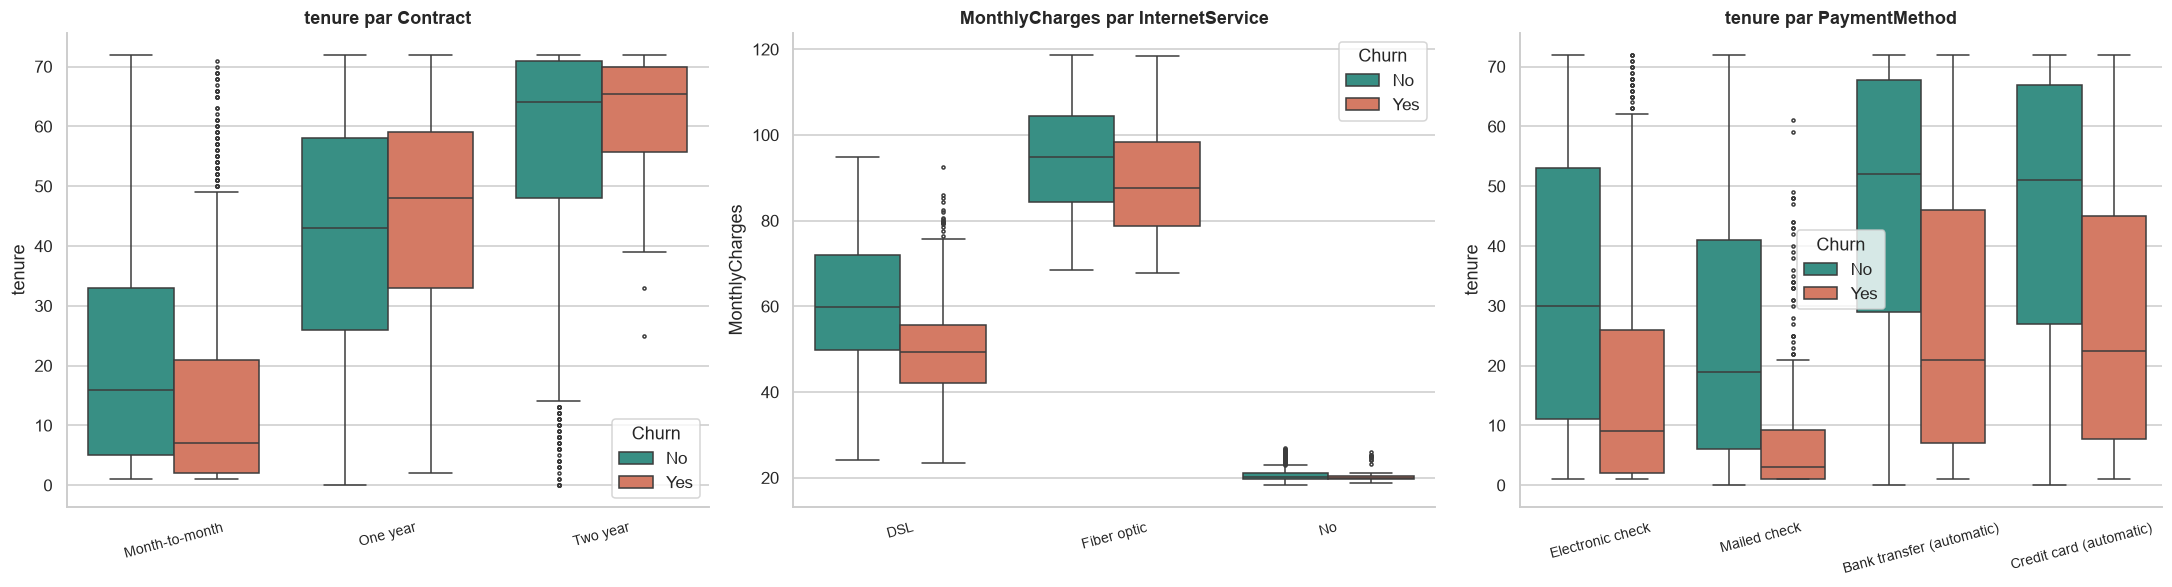

In [38]:
h('### 8.5 Variables numériques selon les catégories clés, séparées par churn')
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (cat, numv, ttl) in zip(axes, [('Contract', df['tenure'], 'tenure'),
                                         ('InternetService', df['MonthlyCharges'], 'MonthlyCharges'),
                                         ('PaymentMethod', df['tenure'], 'tenure')]):
    d = pd.DataFrame({'cat': df[cat], 'v': numv, 'Churn': df[TARGET]})
    sns.boxplot(data=d, x='cat', y='v', hue='Churn', palette=PALETTE, ax=ax, fliersize=2)
    ax.set_title(f'{ttl} par {cat}'); ax.set_xlabel(''); ax.set_ylabel(ttl)
    ax.tick_params(axis='x', labelrotation=15, labelsize=9)
plt.tight_layout(); plt.show()

---
## 9. Segments à risque : où se concentre le churn ?
**Objectif :** passer de « quelles variables comptent » à « quels clients cibler en priorité ».

**Segments Contract × InternetService × PaymentMethod (≥ 100 clients) : 10 plus risqués**

taux churn  clients  churners
Contract       InternetService PaymentMethod                                           
Month-to-month Fiber optic     Electronic check                0.604     1307       789
                               Mailed check                    0.507      201       102
                               Bank transfer (automatic)       0.456      327       149
                               Credit card (automatic)         0.416      293       122
               DSL             Electronic check                0.405      474       192
                               Mailed check                    0.308      367       113
                               Credit card (automatic)         0.270      185        50
One year       Fiber optic     Electronic check                0.260      196        51
Month-to-month No              Mailed check                    0.206      325        67
               DSL             Bank transfer (automatic)       0.198      197        39

**10 plus sûrs**

taux churn  clients  churners
Contract InternetService PaymentMethod                                           
Two year DSL             Mailed check                    0.000      109         0
         No              Bank transfer (automatic)       0.006      178         1
                         Mailed check                    0.008      252         2
                         Credit card (automatic)         0.011      190         2
One year No              Mailed check                    0.012      164         2
Two year DSL             Bank transfer (automatic)       0.013      224         3
                         Credit card (automatic)         0.021      237         5
         Fiber optic     Credit card (automatic)         0.039      154         6
One year DSL             Bank transfer (automatic)       0.076      145        11
Two year Fiber optic     Bank transfer (automatic)       0.093      162        15

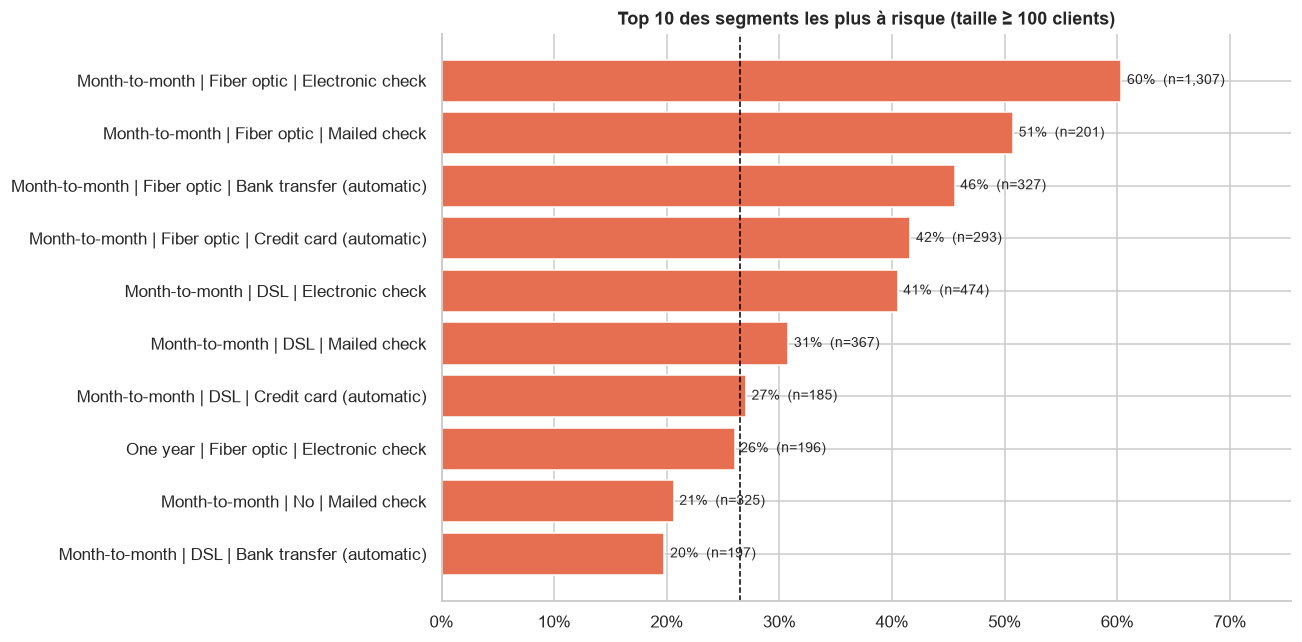

In [39]:
seg_cols = [df['Contract'], df['InternetService'], df['PaymentMethod']]
seg = churn_mask.groupby(seg_cols).agg(['mean', 'size', 'sum'])
seg.columns = ['taux churn', 'clients', 'churners']
seg = seg[seg['clients'] >= 100].sort_values('taux churn', ascending=False)

h('**Segments Contract × InternetService × PaymentMethod (≥ 100 clients) : 10 plus risqués**')
display(seg.head(10))
h('**10 plus sûrs**')
display(seg.tail(10).iloc[::-1])

top = seg.head(10).iloc[::-1]
labels = [' | '.join(map(str, idx)) for idx in top.index]
fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(labels, top['taux churn'], color=C_CHURN)
for i, (r, n) in enumerate(zip(top['taux churn'], top['clients'])):
    ax.text(r + .005, i, f'{r:.0%}  (n={n:,})', va='center', fontsize=9)
ax.axvline(overall_rate, color='black', ls='--', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, top['taux churn'].max() * 1.25)
ax.set_title('Top 10 des segments les plus à risque (taille ≥ 100 clients)')
plt.tight_layout(); plt.show()

### 9.2 Concentration du churn : part des clients vs part des churners

clients  churners  taux churn  part des clients  part des churners
Contract       InternetService                                                                    
Month-to-month Fiber optic         2128      1162       0.546             0.302              0.622
               DSL                 1223       394       0.322             0.174              0.211
One year       Fiber optic          539       104       0.193             0.077              0.056
Month-to-month No                   524        99       0.189             0.074              0.053
One year       DSL                  570        53       0.093             0.081              0.028
Two year       Fiber optic          429        31       0.072             0.061              0.017
               DSL                  628        12       0.019             0.089              0.006
One year       No                   364         9       0.025             0.052              0.005
Two year       No                   638         5       0.008             0.091              0.003

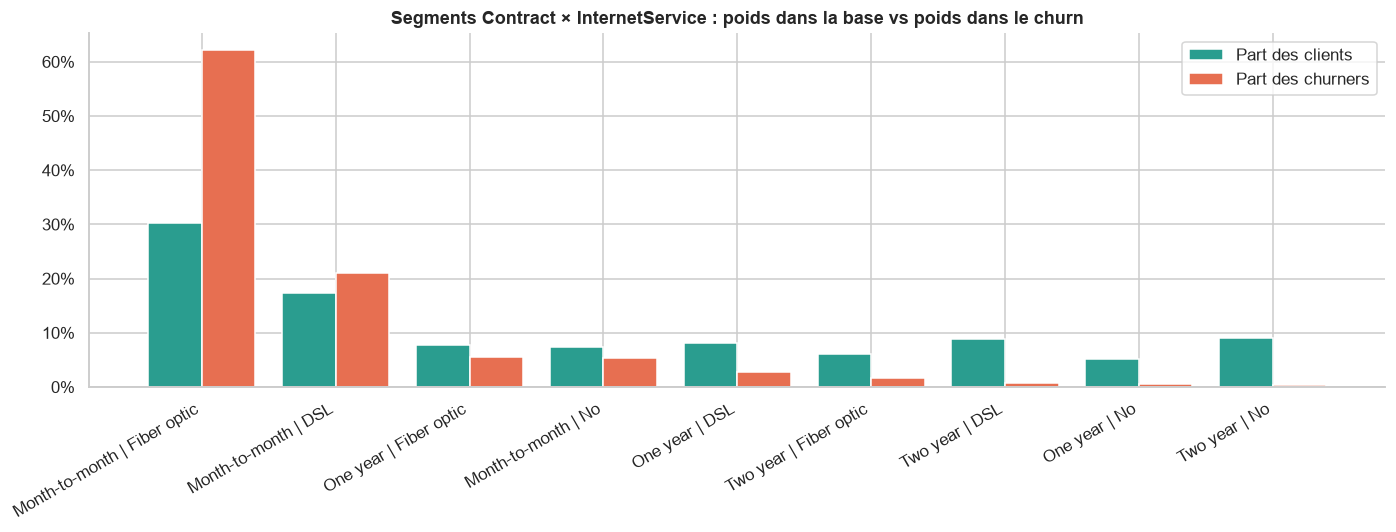

2 segment(s) sur 9 regroupent 83% des churners.


In [40]:
h('### 9.2 Concentration du churn : part des clients vs part des churners')
c2 = churn_mask.groupby([df['Contract'], df['InternetService']]).agg(['sum', 'size'])
c2['part des clients'] = c2['size'] / c2['size'].sum()
c2['part des churners'] = c2['sum'] / c2['sum'].sum()
c2['taux churn'] = c2['sum'] / c2['size']
c2 = c2.sort_values('part des churners', ascending=False)
display(c2[['size', 'sum', 'taux churn', 'part des clients', 'part des churners']].rename(columns={'size': 'clients', 'sum': 'churners'}))

x = np.arange(len(c2)); w = .4
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - w / 2, c2['part des clients'], w, color=C_STAY, label='Part des clients')
ax.bar(x + w / 2, c2['part des churners'], w, color=C_CHURN, label='Part des churners')
ax.set_xticks(x); ax.set_xticklabels([' | '.join(map(str, i)) for i in c2.index], rotation=30, ha='right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
ax.set_title('Segments Contract × InternetService : poids dans la base vs poids dans le churn')
plt.tight_layout(); plt.show()

cum = c2['part des churners'].cumsum()
n_seg = int((cum < .8).sum() + 1)
print(f'{n_seg} segment(s) sur {len(c2)} regroupent {cum.iloc[n_seg - 1]:.0%} des churners.')

---
## 10. Impact business : revenu en jeu
**Objectif :** traduire le churn en euros/dollars, argument clé pour le volet « Value » du pitch. (Estimation simple basée sur MonthlyCharges, à présenter comme un ordre de grandeur.)

Revenu mensuel total de la base        : 456,117
Revenu mensuel porté par les partis    : 139,131  (30.5% du total)
Extrapolation annualisée (×12)         : 1,669,570
Panier moyen mensuel : partis 74.44  vs  restés 61.27


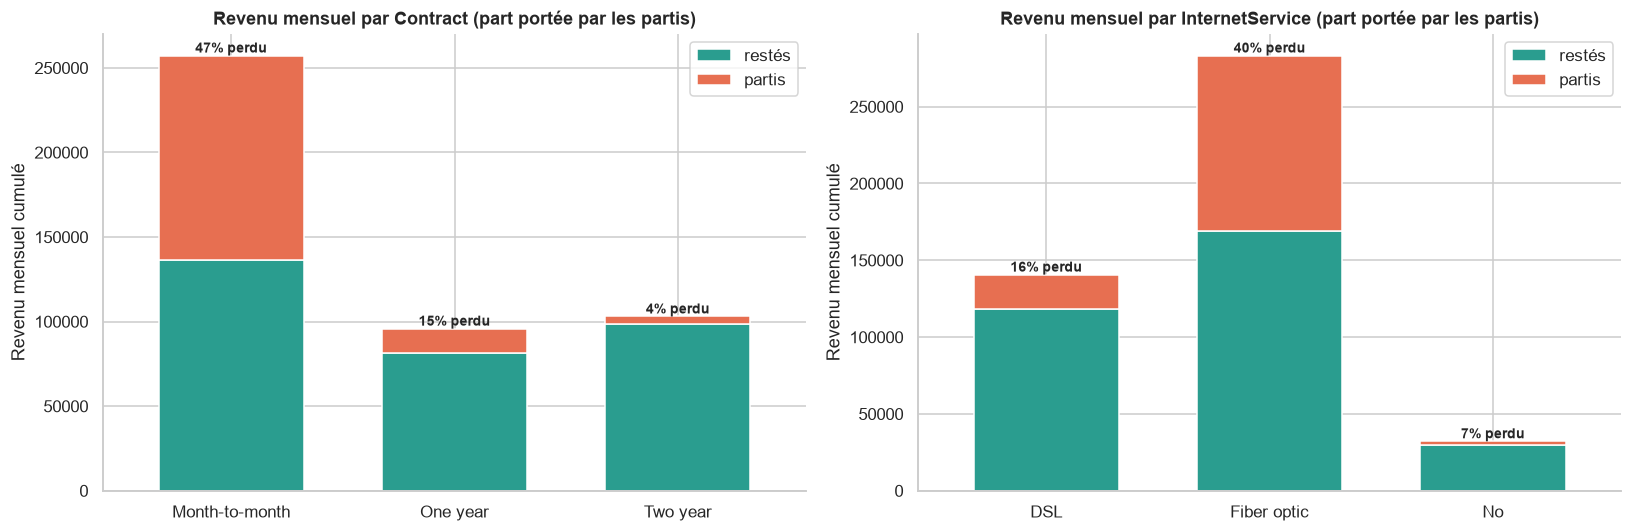

In [41]:
m = df['MonthlyCharges']
rev_total, rev_lost = m.sum(), m[churn_mask].sum()
print(f'Revenu mensuel total de la base        : {rev_total:,.0f}')
print(f'Revenu mensuel porté par les partis    : {rev_lost:,.0f}  ({rev_lost / rev_total:.1%} du total)')
print(f'Extrapolation annualisée (×12)         : {rev_lost * 12:,.0f}')
print(f'Panier moyen mensuel : partis {m[churn_mask].mean():.2f}  vs  restés {m[~churn_mask].mean():.2f}')

by_c = pd.DataFrame({'restés': m[~churn_mask].groupby(df.loc[~churn_mask, 'Contract']).sum(),
                     'partis': m[churn_mask].groupby(df.loc[churn_mask, 'Contract']).sum()}).fillna(0)
by_i = pd.DataFrame({'restés': m[~churn_mask].groupby(df.loc[~churn_mask, 'InternetService']).sum(),
                     'partis': m[churn_mask].groupby(df.loc[churn_mask, 'InternetService']).sum()}).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, t, ttl in zip(axes, [by_c, by_i], ['Contract', 'InternetService']):
    t.plot(kind='bar', stacked=True, color=[C_STAY, C_CHURN], ax=ax, width=.65)
    for i, (idx, r) in enumerate(t.iterrows()):
        tot = r.sum()
        if tot > 0:
            ax.text(i, tot, f"{r['partis'] / tot:.0%} perdu", ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_title(f'Revenu mensuel par {ttl} (part portée par les partis)'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
    ax.set_ylabel('Revenu mensuel cumulé')
plt.tight_layout(); plt.show()

---
## 11. Lentille Responsible AI : attributs sensibles et proxys
**Objectif :** documenter, par l'analyse seule, (a) si `gender` / `SeniorCitizen` sont liés au churn, (b) s'ils sont corrélés à d'autres variables (**proxys** possibles). C'est un constat d'EDA ; la décision (exclure, surveiller) sera prise lors de la modélisation.

,écart max de taux de churn entre modalités,V de Cramér,p-value,verdict
attribut,,,,
gender,0.008,0.000,0.470,pas de lien significatif
SeniorCitizen,0.181,0.150,0.000,lien statistique


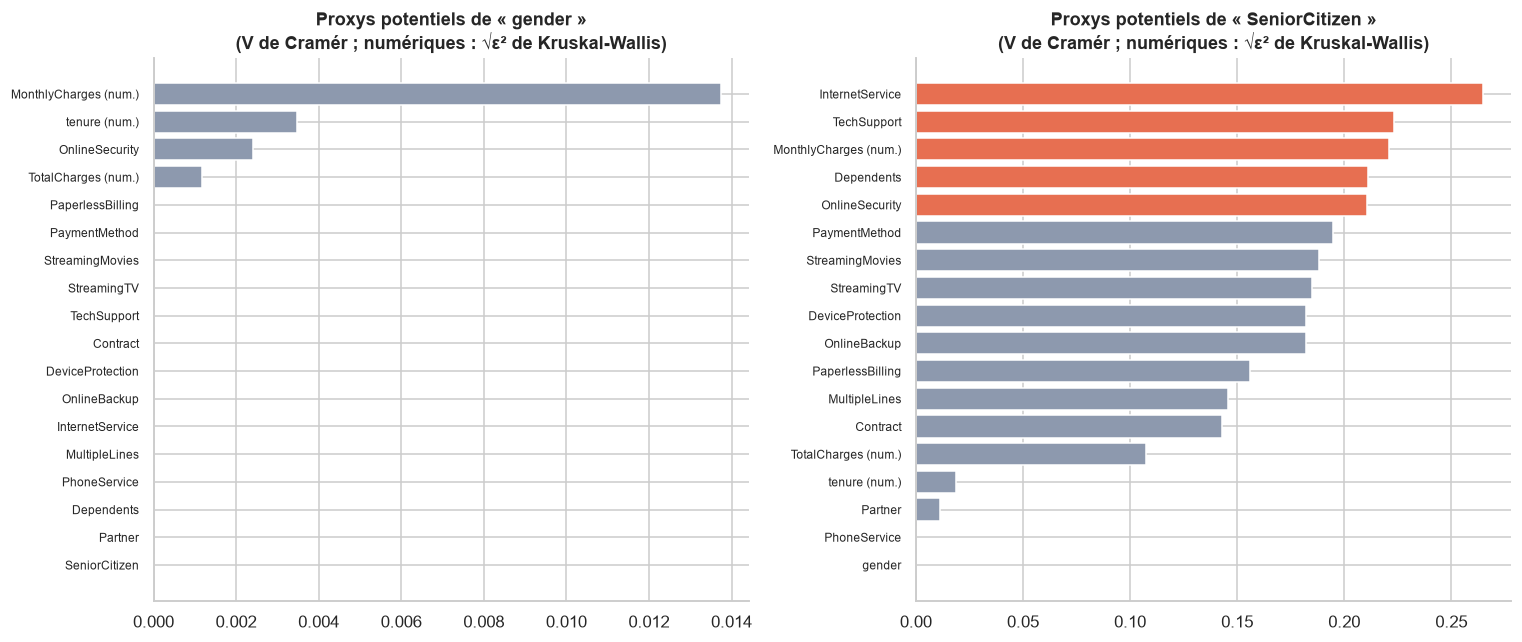

Lecture : une barre rouge (≥ 0,2) signale une variable qui pourrait « re-révéler » l'attribut sensible si celui-ci était exclu.


In [42]:
rows = []
for c in SENSITIVE:
    g = churn_mask.groupby(df[c]).agg(['mean', 'size'])
    v, chi2, p = cramers_v(df[c], df[TARGET])
    rows.append({'attribut': c, 'écart max de taux de churn entre modalités': g['mean'].max() - g['mean'].min(),
                 'V de Cramér': v, 'p-value': p, 'verdict': 'lien statistique' if p < .05 else 'pas de lien significatif'})
display(pd.DataFrame(rows).set_index('attribut'))

# Proxys : lien de chaque attribut sensible avec les autres variables (aucun encodage)
fig, axes = plt.subplots(1, len(SENSITIVE), figsize=(7 * len(SENSITIVE), 6))
for ax, s_attr in zip(np.atleast_1d(axes), SENSITIVE):
    rows = [(c, cramers_v(df[s_attr], df[c])[0]) for c in CAT if c != s_attr]
    for n_ in NUM:
        x = df[n_] if n_ != 'TotalCharges' else total_charges
        grp = [x[df[s_attr] == lvl].dropna() for lvl in df[s_attr].unique()]
        H, _ = stats.kruskal(*grp)
        rows.append((n_ + ' (num.)', np.sqrt(H / (len(x.dropna()) - 1))))
    pr = pd.DataFrame(rows, columns=['variable', 'force']).sort_values('force')
    ax.barh(pr['variable'], pr['force'], color=[C_CHURN if v >= .2 else C_GREY for v in pr['force']])
    ax.set_title(f'Proxys potentiels de « {s_attr} »\n(V de Cramér ; numériques : √ε² de Kruskal-Wallis)')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Lecture : une barre rouge (≥ 0,2) signale une variable qui pourrait « re-révéler » l\'attribut sensible si celui-ci était exclu.')

---
## 12. Synthèse : enseignements clés (générés automatiquement)
Les phrases ci-dessous sont **calculées à partir des données** : elles se mettent à jour toutes seules et sont directement réutilisables dans le pitch.

In [43]:
facts = []
facts.append(f"**Taille & cible** : {len(df):,} clients, taux de churn global de **{overall_rate:.1%}** (ratio {n_stay / n_churn:.1f} : 1, jeu déséquilibré).")

top_vars = assoc.head(5)
facts.append('**Top 5 variables catégorielles liées au churn** : ' + ', '.join(f"{r['variable']} (V={r['V de Cramér']:.2f})" for _, r in top_vars.iterrows()) + '.')

worst, best = mod_table.iloc[0], mod_table.iloc[-1]
facts.append(f"**Modalité la plus à risque** : {worst['variable']} = {worst['modalité']} → {worst['taux churn']:.0%} de churn (×{worst['lift vs global']:.1f} vs la moyenne). "
             f"**Plus protectrice** : {best['variable']} = {best['modalité']} → {best['taux churn']:.0%}.")

mt, mr = df.loc[churn_mask, 'tenure'].median(), df.loc[~churn_mask, 'tenure'].median()
facts.append(f"**Ancienneté** : médiane de {mt:.0f} mois chez les partis contre {mr:.0f} mois chez les restés ; churn de {early:.0%} avant 12 mois contre {late:.0%} après.")

mp, mq = df.loc[churn_mask, 'MonthlyCharges'].median(), df.loc[~churn_mask, 'MonthlyCharges'].median()
facts.append(f"**Prix** : facture mensuelle médiane de {mp:.0f} chez les partis contre {mq:.0f} chez les restés.")

s0 = seg.iloc[0]
facts.append(f"**Segment le plus risqué (≥ 100 clients)** : {' | '.join(map(str, seg.index[0]))} → {s0['taux churn']:.0%} de churn sur {int(s0['clients']):,} clients.")
facts.append(f"**Revenu en jeu** : les partis portaient {rev_lost / rev_total:.1%} du revenu mensuel, soit environ {rev_lost * 12:,.0f} par an (extrapolation simple).")
facts.append(f"**Concentration** : {n_seg} segment(s) Contract × InternetService regroupent {cum.iloc[n_seg - 1]:.0%} des churners.")

for f in facts:
    h('- ' + f)

- **Taille & cible** : 7,043 clients, taux de churn global de **26.5%** (ratio 2.8 : 1, jeu déséquilibré).

- **Top 5 variables catégorielles liées au churn** : Contract (V=0.41), OnlineSecurity (V=0.35), TechSupport (V=0.34), InternetService (V=0.32), PaymentMethod (V=0.30).

- **Modalité la plus à risque** : PaymentMethod = Electronic check → 45% de churn (×1.7 vs la moyenne). **Plus protectrice** : Contract = Two year → 3%.

- **Ancienneté** : médiane de 10 mois chez les partis contre 38 mois chez les restés ; churn de 47% avant 12 mois contre 17% après.

- **Prix** : facture mensuelle médiane de 80 chez les partis contre 64 chez les restés.

- **Segment le plus risqué (≥ 100 clients)** : Month-to-month | Fiber optic | Electronic check → 60% de churn sur 1,307 clients.

- **Revenu en jeu** : les partis portaient 30.5% du revenu mensuel, soit environ 1,669,570 par an (extrapolation simple).

- **Concentration** : 2 segment(s) Contract × InternetService regroupent 83% des churners.

In [44]:
h('### Problèmes de données détectés (constats uniquement : le traitement relève du notebook suivant)')
issues = []
if bad.any():
    issues.append(('TotalCharges', 'Stockée en texte ; ' + str(int(bad.sum())) + ' valeur(s) vide(s)/non numérique(s), toutes associées à tenure = 0' if set(df.loc[bad, 'tenure']) == {0} else 'Stockée en texte avec valeurs non numériques'))
issues.append(('Churn', 'Cible textuelle Yes/No'))
if 'SeniorCitizen' in df.columns and df['SeniorCitizen'].dtype != object:
    issues.append(('SeniorCitizen', 'Codée 0/1 alors que les autres binaires sont Yes/No (incohérence de format)'))
if (df['InternetService'] == 'No').any():
    issues.append(('Services Internet / MultipleLines', "Modalités « No internet service » / « No phone service » : redondantes avec InternetService / PhoneService"))
issues.append((ID, 'Identifiant unique, sans valeur prédictive'))
issues.append(('gender, SeniorCitizen', 'Attributs sensibles : à traiter selon la section 11'))
issues.append(('tenure ↔ TotalCharges', f'Forte corrélation ({cr:.2f}) : multicolinéarité à surveiller'))
display(pd.DataFrame(issues, columns=['élément', 'constat']).set_index('élément'))

### Problèmes de données détectés (constats uniquement : le traitement relève du notebook suivant)

,constat
élément,
TotalCharges,Stockée en texte ; 11 valeur(s) vide(s)/non nu...
Churn,Cible textuelle Yes/No
SeniorCitizen,Codée 0/1 alors que les autres binaires sont Y...
Services Internet / MultipleLines,Modalités « No internet service » / « No phone...
customerID,"Identifiant unique, sans valeur prédictive"
"gender, SeniorCitizen",Attributs sensibles : à traiter selon la secti...
tenure ↔ TotalCharges,Forte corrélation (0.83) : multicolinéarité à ...


### ➡️ Prochaine étape
**Notebook 2 : preprocessing et feature engineering** (traitement de TotalCharges, encodage de la cible et des catégories, exclusion des attributs sensibles, pipeline). Tout ce qui a été *détecté* ici y sera *traité*.